# Results

216 OASIS-1 patients with complete clinical data and all five MRI image types (no imputation), k = 4 clusters
for every configuration. Configurations are compared with the Pairwise Separability Index (PSI) on Age, MMSE,
nWBV, eTIV, CDR (|Cliff's δ|) and Education, SES, sex (Total Variation Distance); the one with the highest PSI is
selected.

Figures and tables come from notebooks 01–07 and are saved in `results/`.

1. Changes from the previous analysis
2. Implementation
3. Configurations
4. Number of clusters
5. Pairwise Separability Index
6. Clusters of every configuration
7. Clusters in three dimensions
8. Cluster profiles of every configuration
9. Selected configuration
10. Stability
11. Robustness checks and secondary results
12. Comparison with the previous method

In [1]:
%run -i ../src/setup.ipynb
import json
from IPython.display import Image, Markdown
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist, squareform

R = cfg.RESULTS_DIR
OUT = R / "09_results"
OUT.mkdir(parents=True, exist_ok=True)

def show_png(path, width=1000):
    display(Image(filename=str(path), width=width))

selection = json.loads((R / "02_compare_configurations" / "selection.json").read_text())
K = selection["k"]
labels = pd.read_csv(R / "02_compare_configurations" / "labels.csv")
psi = pd.read_csv(R / "02_compare_configurations" / "psi_table.csv", index_col=0)
df = load_analysis_data()
assert (labels["patient_id"] == df["patient_id"]).all()
ORDER = list(psi.loc["PSI (mean)"].sort_values(ascending=False).index)

## 1. Changes from the previous analysis

| Issue | Change |
|---|---|
| Configurations were judged by their agreement with CDR (ARI/NMI) | Configurations compared with the PSI; ARI/NMI against CDR kept as secondary results |
| Unscaled clinical variables dominated the distance | Age, MMSE, eTIV and nWBV in a block with robust Mahalanobis distance; ASF removed (r = −0.99 with eTIV); images and clinical variables in separate blocks; images with Euclidean distance |
| Education, SES and sex | In a multiclass block with Hamming distance (one-hot encoded for k-means), and compared with the Total Variation Distance in the PSI |
| Configurations used different samples and selection criteria | Same 216 patients for all configurations; no imputation; one selection rule fixed in advance |
| Software | robust-mixed-dist 0.1.31 and db-robust-clust 0.1.15; `SampleDistClustering` with `frac_sample_size = 1` for every k-medoids configuration; exact RelMS; G-Gower by blocks |

Share of the previous clinical distance (unscaled Euclidean) due to each variable:

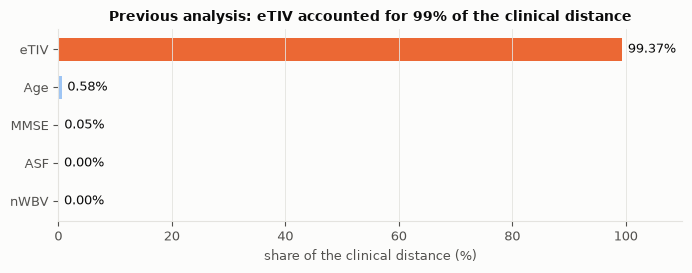

In [2]:
raw = pd.read_excel(cfg.CLINICAL_FILE).rename(columns={"ID": "patient_id"})
raw["patient_id"] = raw["patient_id"].str.replace(r"_MR\d+$", "", regex=True)
old = df[["patient_id", "Age", "MMSE", "eTIV", "nWBV"]].merge(
    raw[["patient_id", "ASF"]].drop_duplicates("patient_id"), on="patient_id")
v = old[["Age", "MMSE", "eTIV", "nWBV", "ASF"]].var()
share = (v / v.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(share.index, share.values, color=[CLUSTER_COLORS[1] if x > 50 else "#9ec5f4" for x in share.values], height=0.6)
for i, x in enumerate(share.values):
    ax.text(x + 1, i, f"{x:.2f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 110)
ax.set_xlabel("share of the clinical distance (%)")
ax.set_title("Previous analysis: eTIV accounted for 99% of the clinical distance")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT / "etiv_share_previous.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Implementation

| Component | Source | Location |
|---|---|---|
| Pairwise Separability Index | `compute_config_pairwise_separability` by F. Scielzo-Ortiz, unchanged (https://hdl.handle.net/10016/51001) | `src/psi.ipynb` |
| Distances (G-Gower, RelMS, robust Mahalanobis) | robust-mixed-dist 0.1.31 | `src/clustering_utils.ipynb` |
| Clustering | `SampleDistClustering` (db-robust-clust 0.1.15), `frac_sample_size = 1`, PAM with `init = 'build'`, 100 iterations, `random_state = 123` | `src/clustering_utils.ipynb` |
| Exact RelMS | subclass of `SampleDistClustering` using `related_metric_scaling_dist_matrix` instead of `related_metric_scaling_dist_matrix_faster` | `src/clustering_utils.ipynb` |
| Robust covariance | `robust_method = 'trimmed'`, α = 0.05 | `src/config.ipynb` |
| Settings and configurations | one configuration object | `src/config.ipynb` |

## 3. Configurations

Image blocks: one per image type (110 PCA scores each), Euclidean distance. Clinical variables: Age, MMSE, eTIV and
nWBV in a quantitative block with robust Mahalanobis distance, and Education, SES and sex in a multiclass block with
Hamming distance. Each configuration differs from its reference in one thing only.

In [3]:
rows = []
for name, c in cfg.CONFIGS.items():
    if c["algorithm"] == "kmeans":
        blocks = ("550 image PCs (Euclidean)" if c.get("kmeans_raw") else
                  "standardised clinical + one-hot Education, SES, sex (Euclidean)")
        method = "k-means"
    else:
        img = any(l in cfg.IMAGE_TYPES for l, _, _ in c["quant_blocks"])
        clin = [f"{l} (robust Mahalanobis)" for l, _, d in c["quant_blocks"] if l not in cfg.IMAGE_TYPES]
        cat = ["Education, SES, sex (Hamming)"] if c.get("multiclass") else []
        blocks = " + ".join((["5 image blocks (Euclidean)"] if img else []) + clin + cat)
        method = {"ggower": "G-Gower + PAM", "relms": "RelMS + PAM"}[c["metric"] or selection["m3_metric"]]
    rows.append({"ID": name, "feature space": c["feature_space"], "method": method, "blocks": blocks,
                 "tests": c["description"]})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index("ID")

,feature space,method,blocks,tests
ID,,,,
C1,Clinical,G-Gower + PAM,"clinical (robust Mahalanobis) + Education, SES, sex (Hamming)",Clinical baseline
C1-b,Clinical,k-means,"standardised clinical + one-hot Education, SES, sex (Euclidean)",Effect of the algorithm on the same features
C2,Clinical + CDR,G-Gower + PAM,"clinical+CDR (robust Mahalanobis) + Education, SES, sex (Hamming)",Severity as part of the profile
I1,Images,RelMS + PAM,5 image blocks (Euclidean),Image-only structure
I2,Images,G-Gower + PAM,5 image blocks (Euclidean),RelMS vs. G-Gower on images
I2-b,Images,k-means,550 image PCs (Euclidean),Effect of the algorithm on images
M1,Images + clinical,RelMS + PAM,"5 image blocks (Euclidean) + clinical (robust Mahalanobis) + Education, SES, sex (Hamming)",Added value of images
M2,Images + clinical,G-Gower + PAM,"5 image blocks (Euclidean) + clinical (robust Mahalanobis) + Education, SES, sex (Hamming)","Same, with G-Gower"
M3,Images + clinical + CDR,G-Gower + PAM,"5 image blocks (Euclidean) + clinical+CDR (robust Mahalanobis) + Education, SES, sex (Hamming)",Full profile including severity


## 4. Number of clusters

C1, M1 and I1 were fitted for k = 2 to 5, and k was chosen from the cluster profiles and medoids, with the PSI
as support. The other configurations were fitted directly at the chosen k.

| k | Clinical reference configuration C1 | Decision |
|---|---|---|
| 2 | split by sex and head size only (MMSE PSI 0.08, CDR 0.00) | rejected |
| 3 | no impaired cluster (median MMSE 29 in all three) | rejected |
| **4** | younger healthy; mostly men with large heads and high education; lower education; cognitively impaired | **selected** |
| 5 | splits mainly by sex (one cluster 0% men, one 96% men); PSI almost unchanged (0.439 vs 0.434) | rejected |

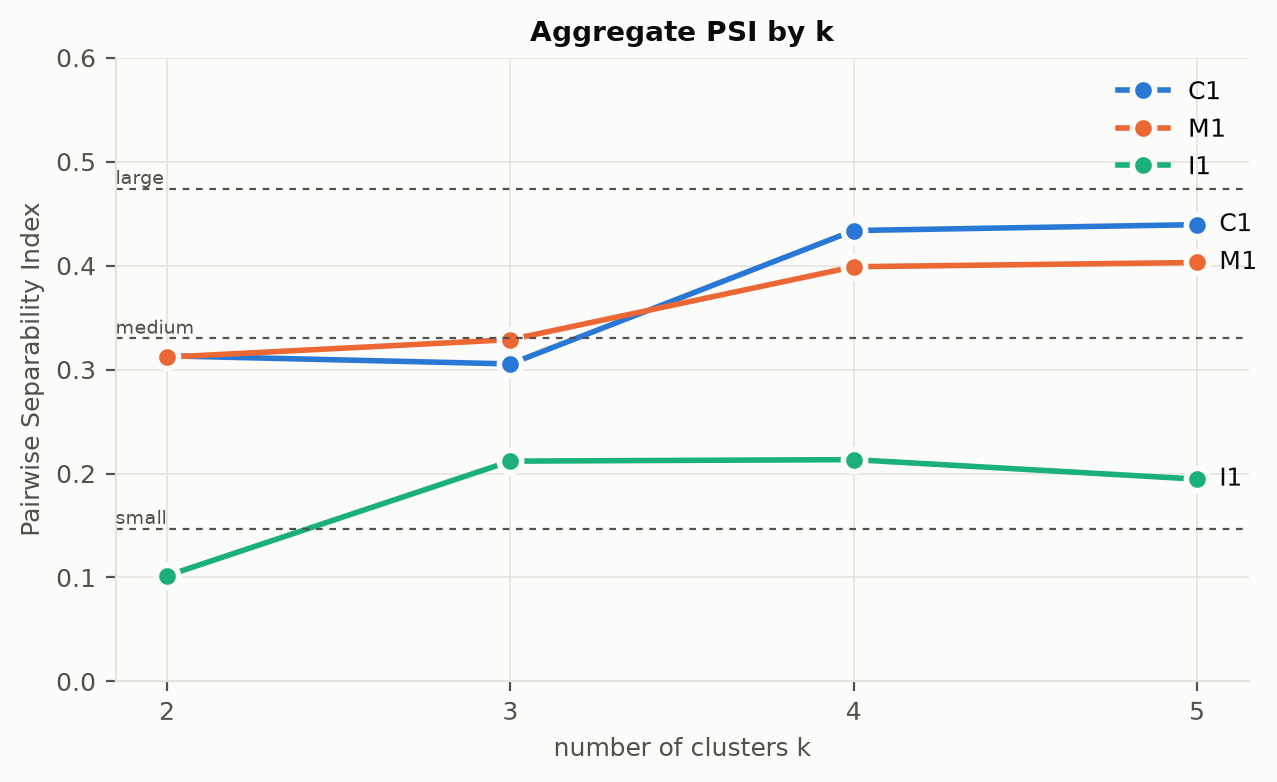

In [4]:
show_png(R / "01_choose_k" / "psi_by_k.png", 650)

## 5. Pairwise Separability Index (k = 4)

Mean |Cliff's δ| (ordered variables) or TVD (Education, SES, sex) over the 6 pairs of clusters. N = negligible (< 0.147),
S = small, M = medium (≥ 0.33), L = large (≥ 0.474). Highest value of each row in bold; configurations ordered by
aggregate PSI.

,C1-b,C1,M2,M1,C2,M3,I2,I1,I2-b
Age,0.507 (L),0.265 (S),0.319 (S),0.263 (S),0.203 (S),0.232 (S),0.300 (S),0.263 (S),0.045 (N)
MMSE,0.646 (L),0.373 (M),0.295 (S),0.368 (M),0.194 (S),0.230 (S),0.213 (S),0.137 (N),0.125 (N)
nWBV,0.712 (L),0.445 (M),0.336 (M),0.480 (L),0.192 (S),0.394 (M),0.364 (M),0.318 (S),0.080 (N)
eTIV,0.530 (L),0.451 (M),0.529 (L),0.315 (S),0.450 (M),0.463 (M),0.223 (S),0.296 (S),0.095 (N)
CDR,0.566 (L),0.346 (M),0.167 (S),0.356 (M),0.228 (S),0.174 (S),0.154 (S),0.134 (N),0.052 (N)
Educ,0.350 (M),0.593 (L),0.483 (L),0.544 (L),0.680 (L),0.421 (M),0.177 (S),0.129 (N),0.219 (S)
SES,0.275 (S),0.674 (L),0.538 (L),0.559 (L),0.576 (L),0.521 (L),0.184 (S),0.154 (S),0.213 (S)
sex,0.392 (M),0.323 (S),0.530 (L),0.307 (S),0.410 (M),0.367 (M),0.132 (N),0.275 (S),0.125 (N)
PSI (mean),0.497 (L),0.434 (M),0.400 (M),0.399 (M),0.367 (M),0.350 (M),0.218 (S),0.213 (S),0.119 (N)


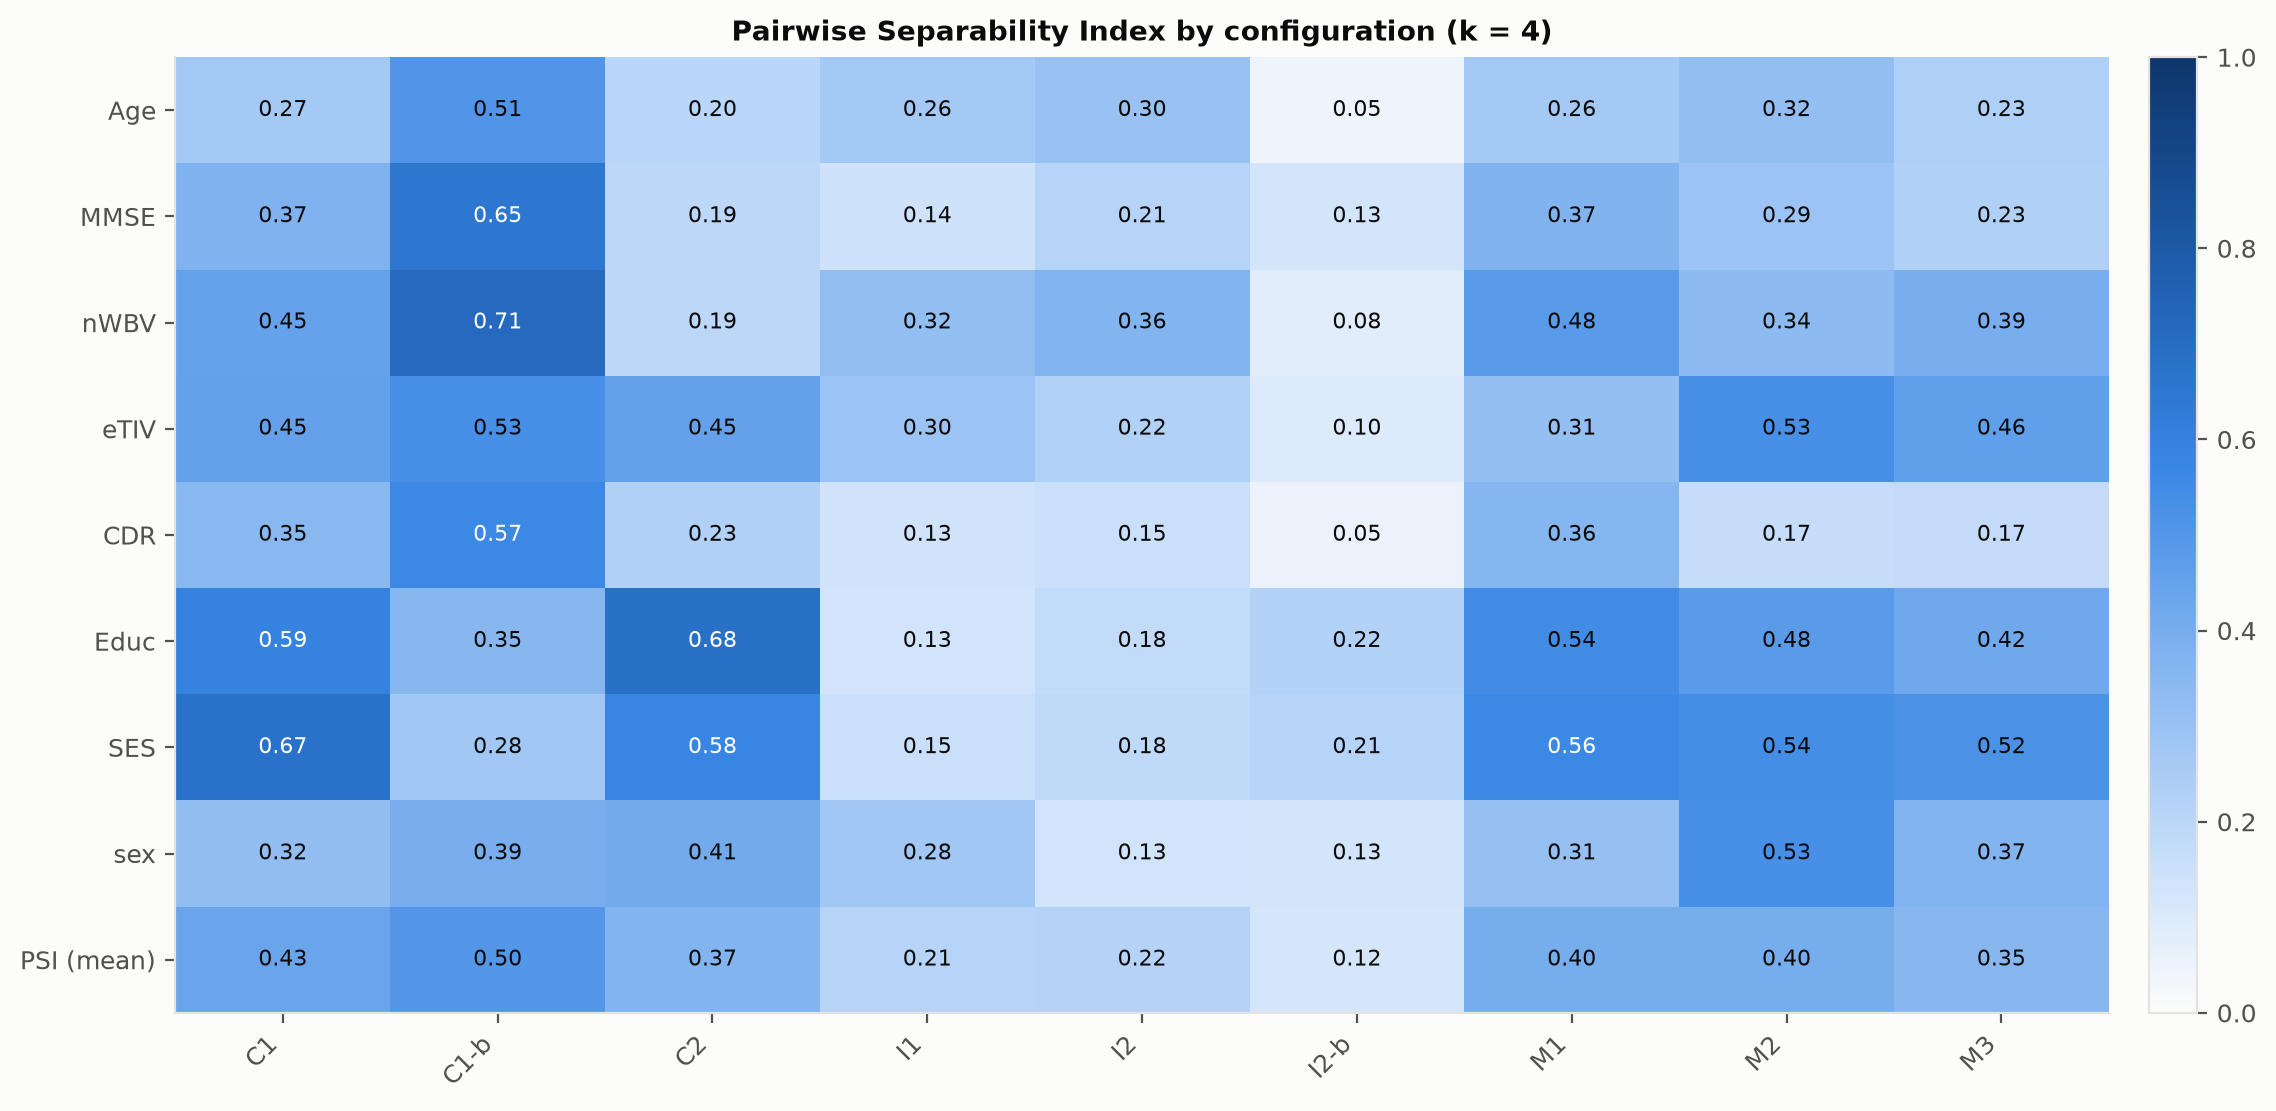

**Selected configuration: C1-b** (aggregate PSI 0.497). M3 uses G-Gower, the better of M1 and M2.

In [5]:
def bold_max(row):
    return ["font-weight: bold" if v == row.max() else "" for v in row]
table = psi[ORDER]
display(format_psi_table(table).style.apply(lambda r: bold_max(table.loc[r.name]), axis=1))
show_png(R / "02_compare_configurations" / "psi_table_heatmap.png", 800)
display(Markdown(f"**Selected configuration: {selection['selected']}** "
                 f"(aggregate PSI {selection['aggregate_psi'][selection['selected']]:.3f}). "
                 f"M3 uses {'G-Gower' if selection['m3_metric'] == 'ggower' else 'RelMS'}, the better of M1 and M2."))

## 6. Clusters of every configuration

Two-dimensional MDS of the distance each configuration was clustered on; each dot is a patient, coloured by
cluster. Clusters are numbered by decreasing mean MMSE, and configurations are ordered by aggregate PSI.

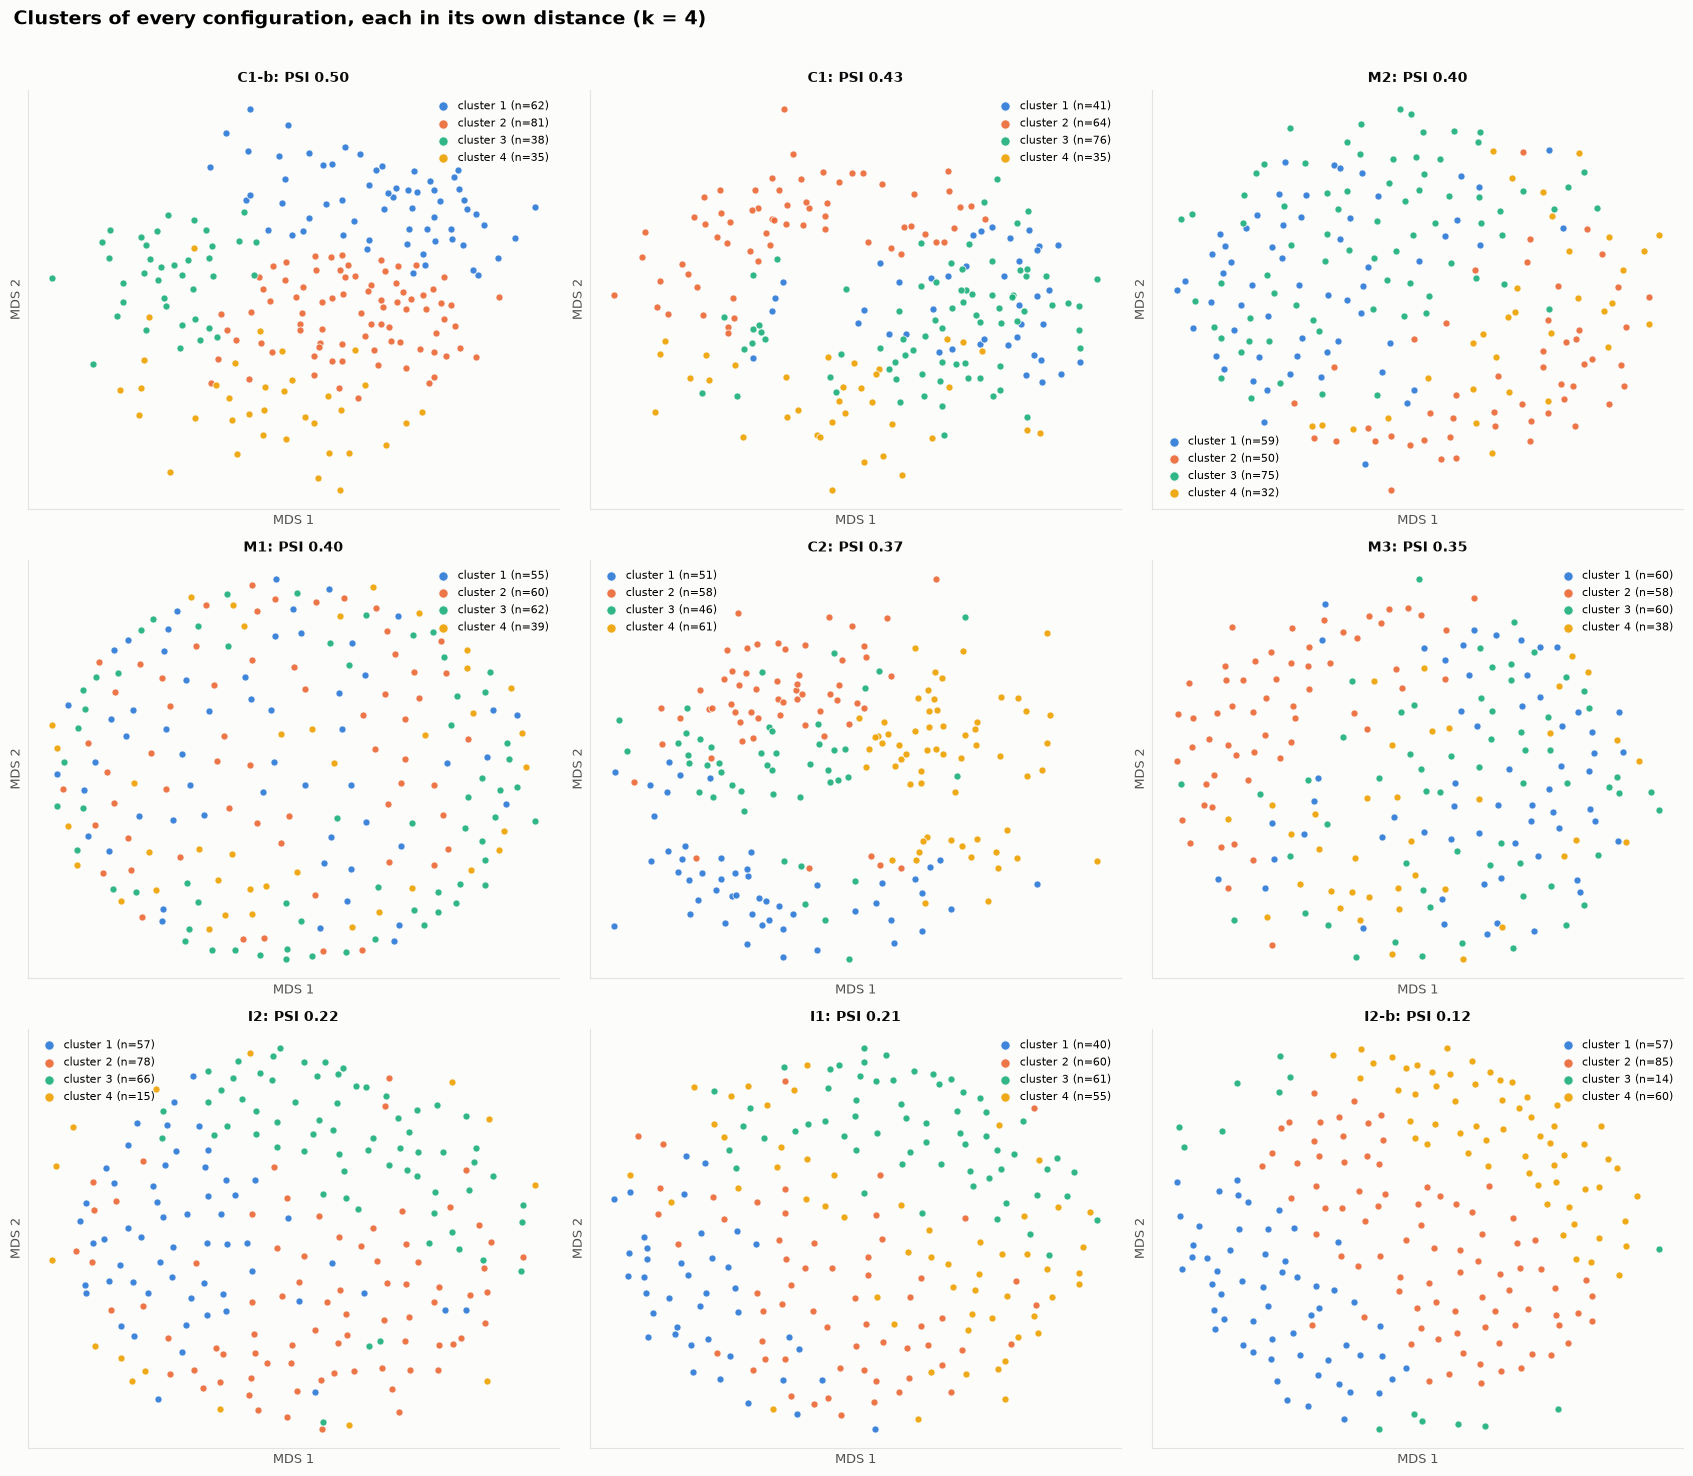

In [6]:
def config_distance(name):
    fit = fit_configuration(name, K, df, metric=selection["m3_metric"] if name == "M3" else None)
    return squareform(pdist(fit["X"])) if fit["D"] is None else fit["D"]

DIST = {name: config_distance(name) for name in ORDER}

fig, axes = plt.subplots(3, 3, figsize=(17, 15))
for ax, name in zip(axes.ravel(), ORDER):
    xy = MDS(n_components=2, metric="precomputed", init="random", n_init=4,
             random_state=42).fit_transform(DIST[name])
    cluster_scatter(ax, xy[:, 0], xy[:, 1], labels[name].to_numpy(),
                    f"{name}: PSI {psi.loc['PSI (mean)', name]:.2f}", "MDS 1", "MDS 2")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Clusters of every configuration, each in its own distance (k = 4)", fontsize=14,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(OUT / "clusters_all_configurations_mds.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Clusters in three dimensions

The same MDS with three axes instead of two, shown as a scatter-plot matrix: each panel below the diagonal is one
pair of axes (1–2, 1–3, 2–3), and the diagonal shows how each cluster is spread along one axis. C1-b is left out
because its clusters are already clearly separated in two dimensions.

The stress (between 0 and 1, lower is better) measures how far the distances on the map are from the real
distances between patients.

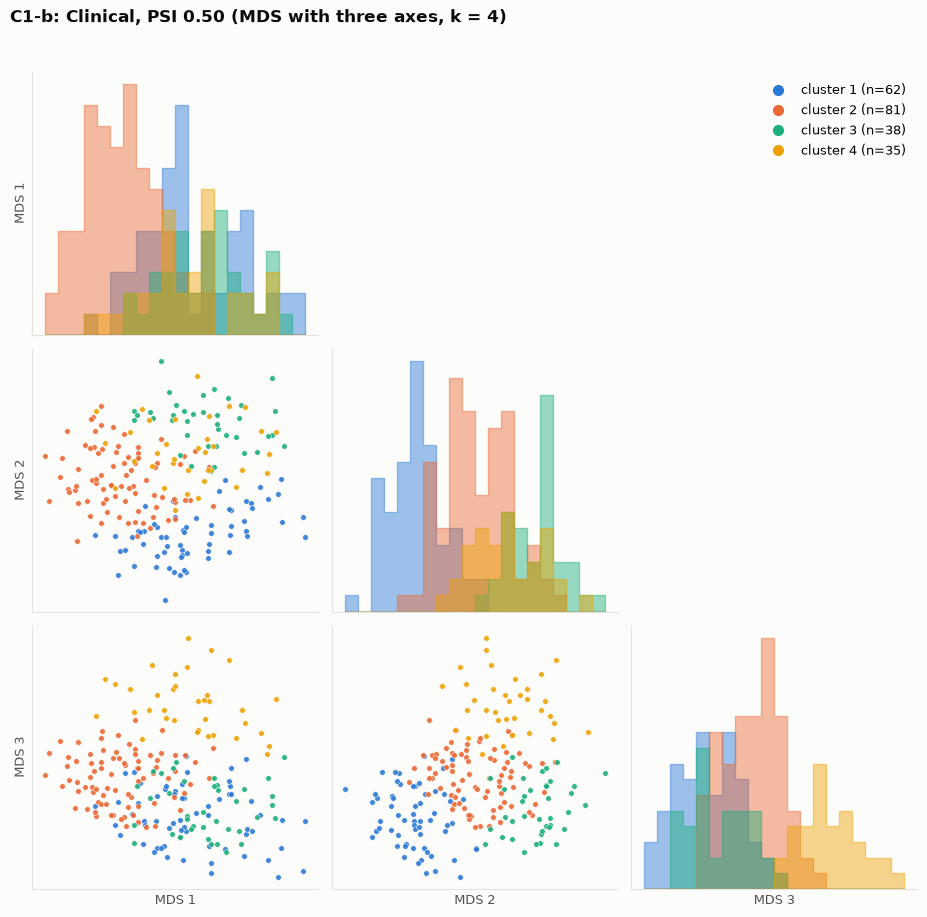

Correlation of each axis with the clinical variables (C1-b):

,MDS 1,MDS 2,MDS 3
Age,-0.460000,0.740000,0.510000
MMSE,-0.230000,-0.330000,-0.850000
nWBV,0.200000,-0.870000,-0.530000
eTIV,0.690000,0.590000,-0.320000
CDR,0.200000,0.400000,0.660000
Education,0.010000,-0.020000,-0.550000
SES,-0.000000,-0.040000,0.520000
sex (1 = man),0.640000,0.390000,-0.140000


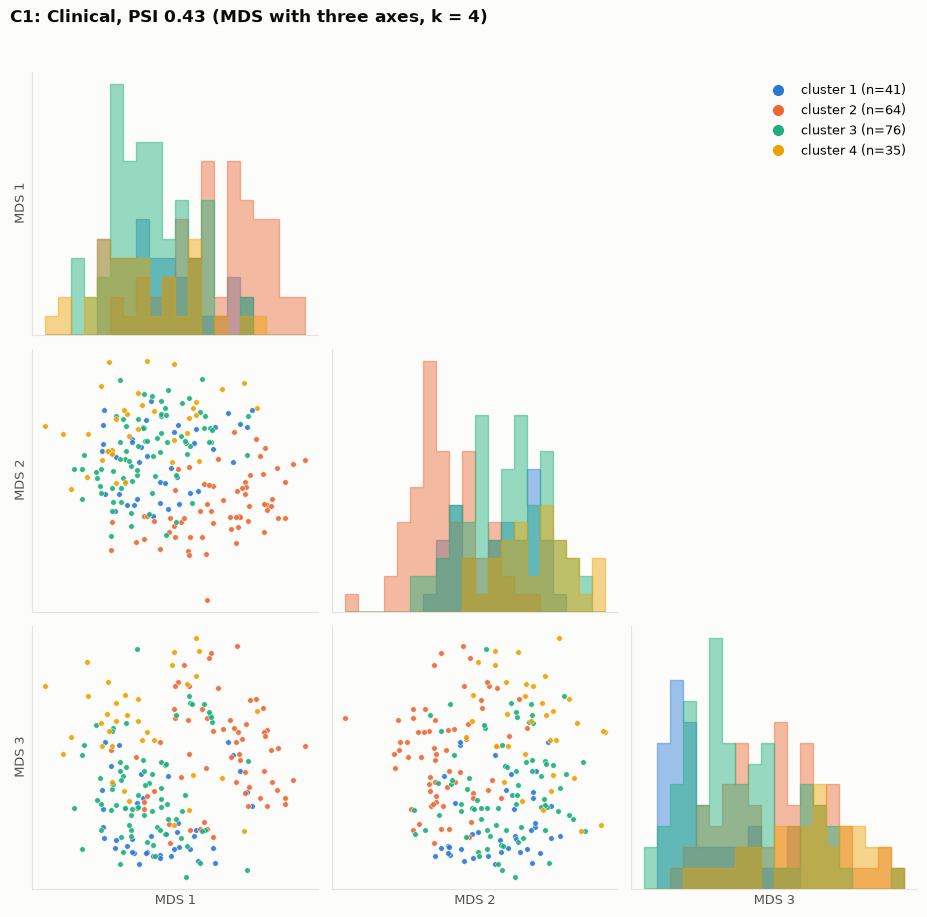

Correlation of each axis with the clinical variables (C1):

,MDS 1,MDS 2,MDS 3
Age,-0.020000,0.360000,0.240000
MMSE,0.040000,-0.440000,-0.460000
nWBV,0.140000,0.040000,-0.670000
eTIV,0.750000,-0.300000,0.340000
CDR,-0.010000,0.280000,0.460000
Education,0.280000,-0.640000,-0.420000
SES,-0.270000,0.650000,0.410000
sex (1 = man),0.740000,-0.250000,0.570000


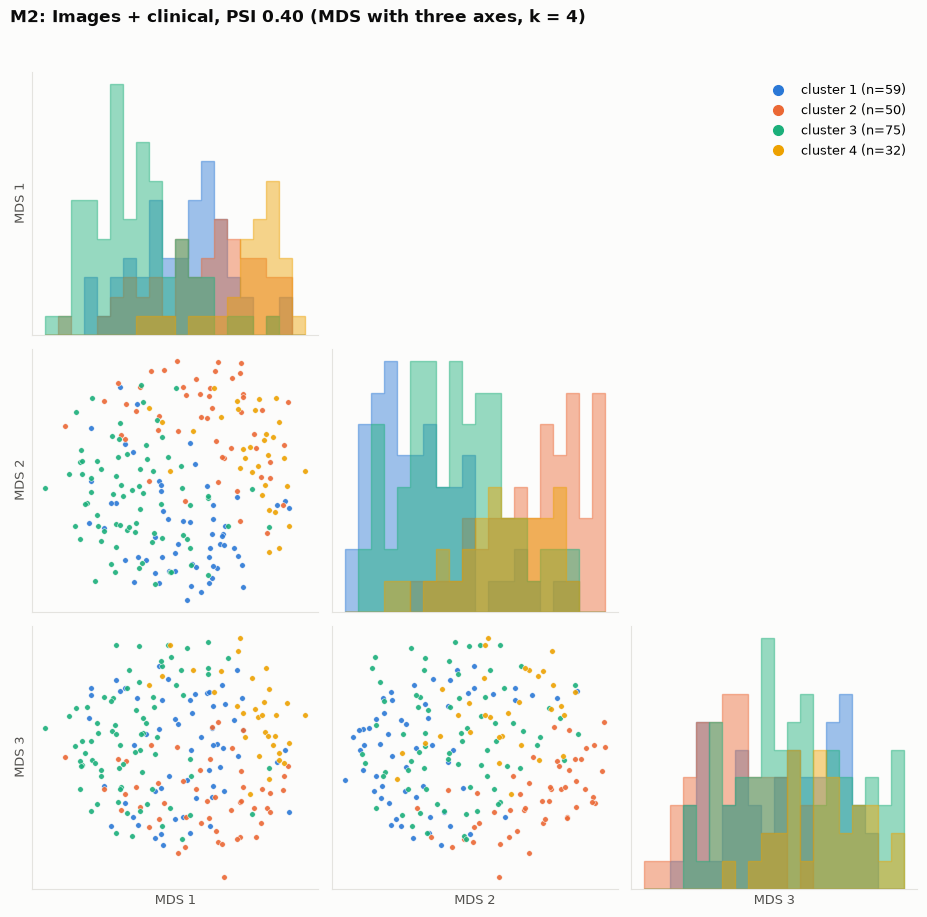

Correlation of each axis with the clinical variables (M2):

,MDS 1,MDS 2,MDS 3
Age,-0.210000,0.420000,0.620000
MMSE,-0.150000,-0.150000,-0.600000
nWBV,0.150000,-0.700000,-0.500000
eTIV,0.480000,0.660000,-0.190000
CDR,0.140000,0.250000,0.460000
Education,-0.200000,0.200000,-0.680000
SES,0.230000,-0.270000,0.660000
sex (1 = man),0.710000,0.470000,-0.220000


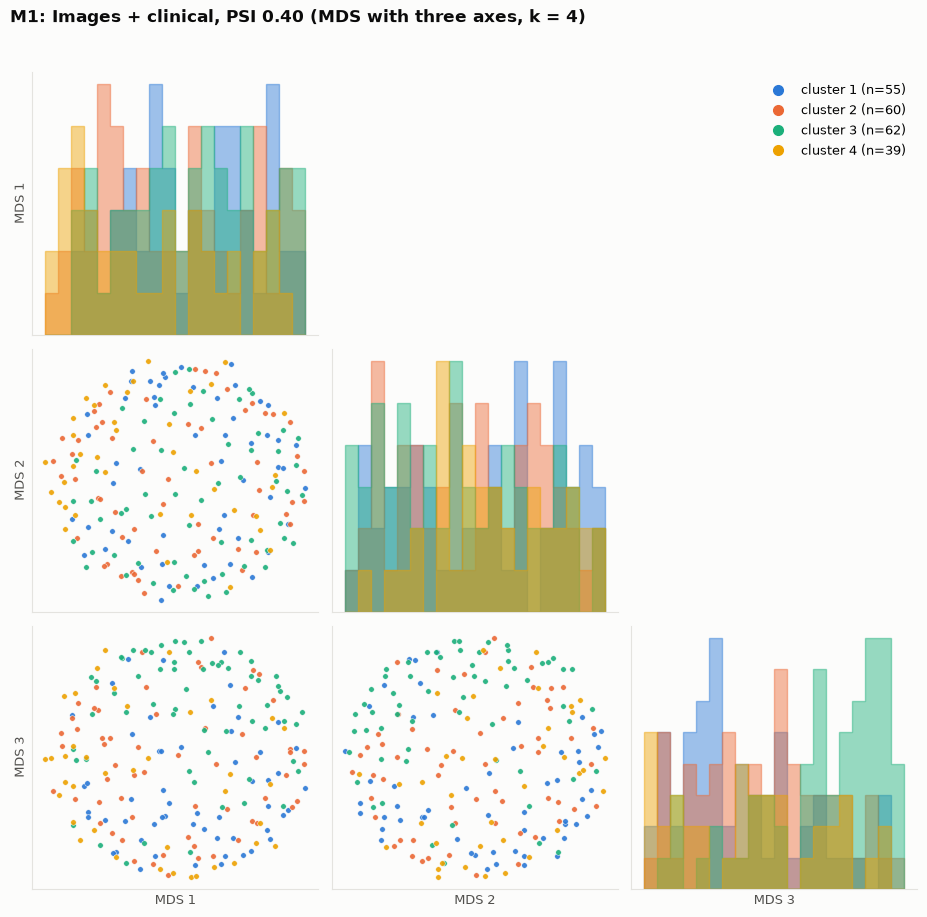

Correlation of each axis with the clinical variables (M1):

,MDS 1,MDS 2,MDS 3
Age,-0.180000,0.100000,-0.060000
MMSE,0.210000,-0.210000,0.030000
nWBV,0.220000,-0.060000,-0.010000
eTIV,-0.090000,-0.080000,0.520000
CDR,-0.180000,0.210000,0.030000
Education,0.280000,-0.090000,0.170000
SES,-0.220000,0.060000,-0.190000
sex (1 = man),0.010000,-0.250000,0.560000


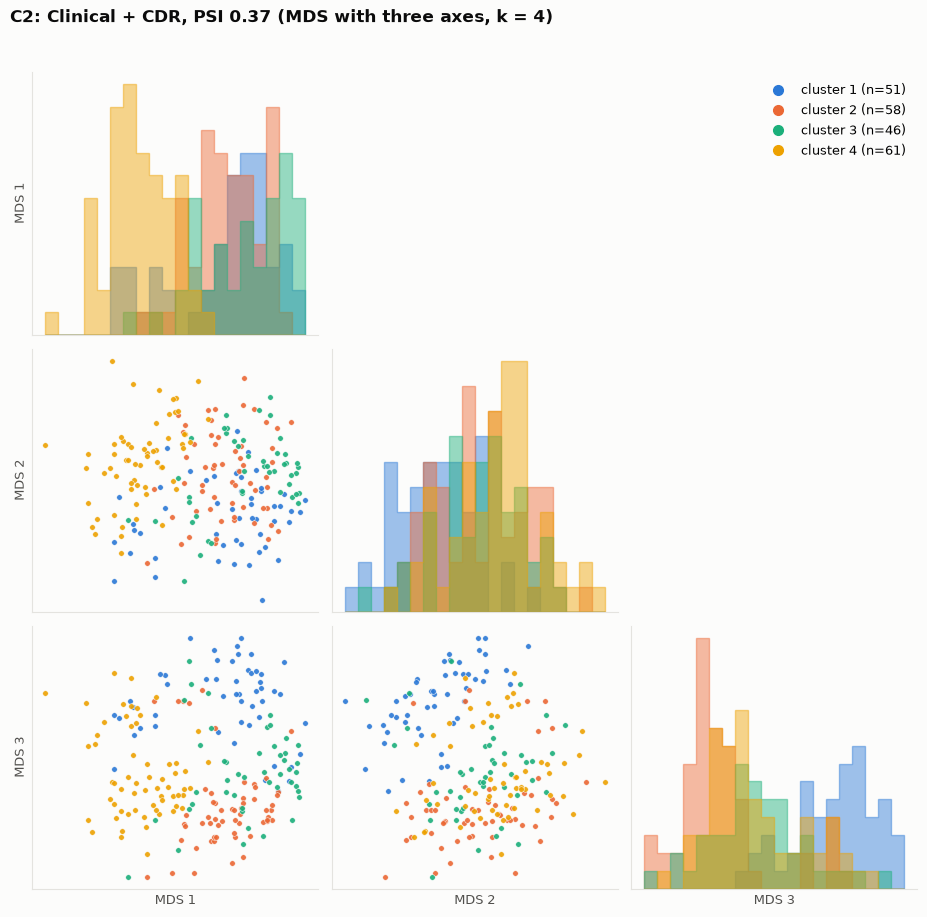

Correlation of each axis with the clinical variables (C2):

,MDS 1,MDS 2,MDS 3
Age,-0.280000,0.290000,0.040000
MMSE,0.520000,0.030000,0.060000
nWBV,0.340000,0.260000,-0.110000
eTIV,0.040000,-0.200000,0.770000
CDR,-0.450000,0.210000,0.140000
Education,0.840000,-0.120000,0.250000
SES,-0.840000,0.120000,-0.260000
sex (1 = man),-0.210000,-0.360000,0.840000


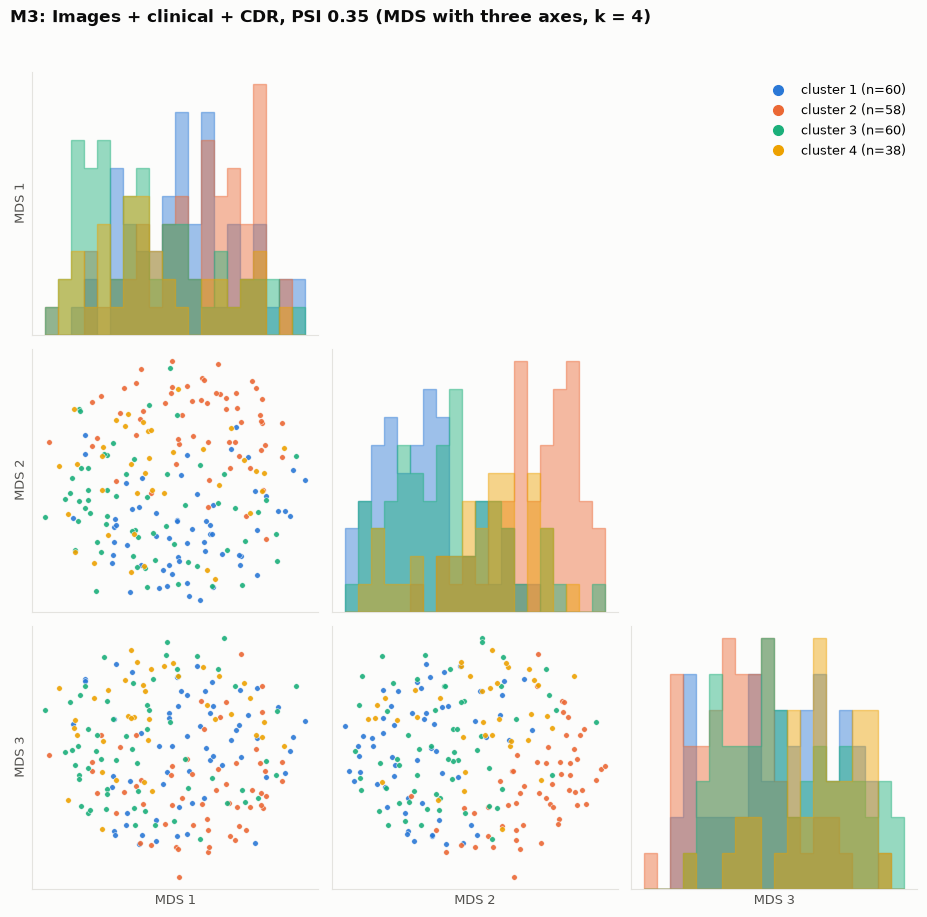

Correlation of each axis with the clinical variables (M3):

,MDS 1,MDS 2,MDS 3
Age,0.020000,0.290000,0.640000
MMSE,-0.170000,-0.120000,-0.440000
nWBV,0.050000,-0.600000,-0.510000
eTIV,0.390000,0.670000,-0.170000
CDR,0.360000,0.110000,0.360000
Education,-0.260000,0.200000,-0.630000
SES,0.290000,-0.260000,0.600000
sex (1 = man),0.620000,0.550000,-0.270000


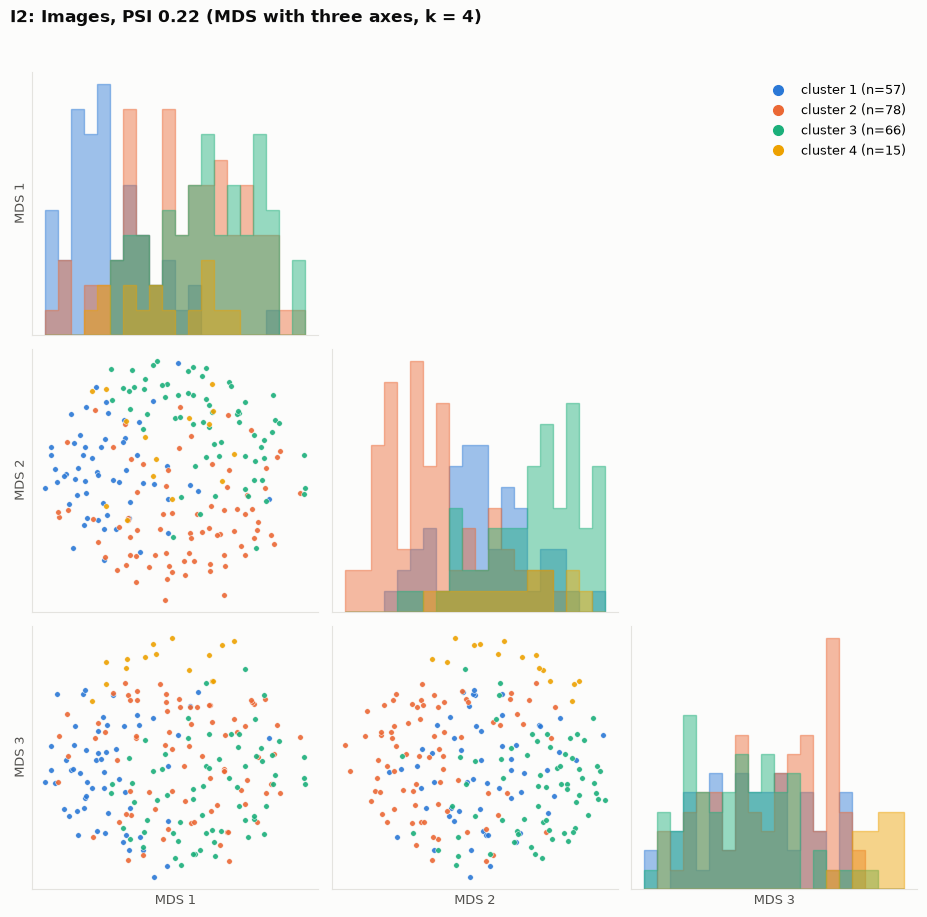

Correlation of each axis with the clinical variables (I2):

,MDS 1,MDS 2,MDS 3
Age,0.420000,-0.330000,0.320000
MMSE,-0.270000,0.020000,-0.110000
nWBV,-0.570000,0.360000,-0.250000
eTIV,0.520000,-0.220000,0.020000
CDR,0.300000,-0.040000,0.200000
Education,0.030000,0.050000,-0.100000
SES,-0.040000,0.010000,0.060000
sex (1 = man),0.440000,-0.070000,-0.180000


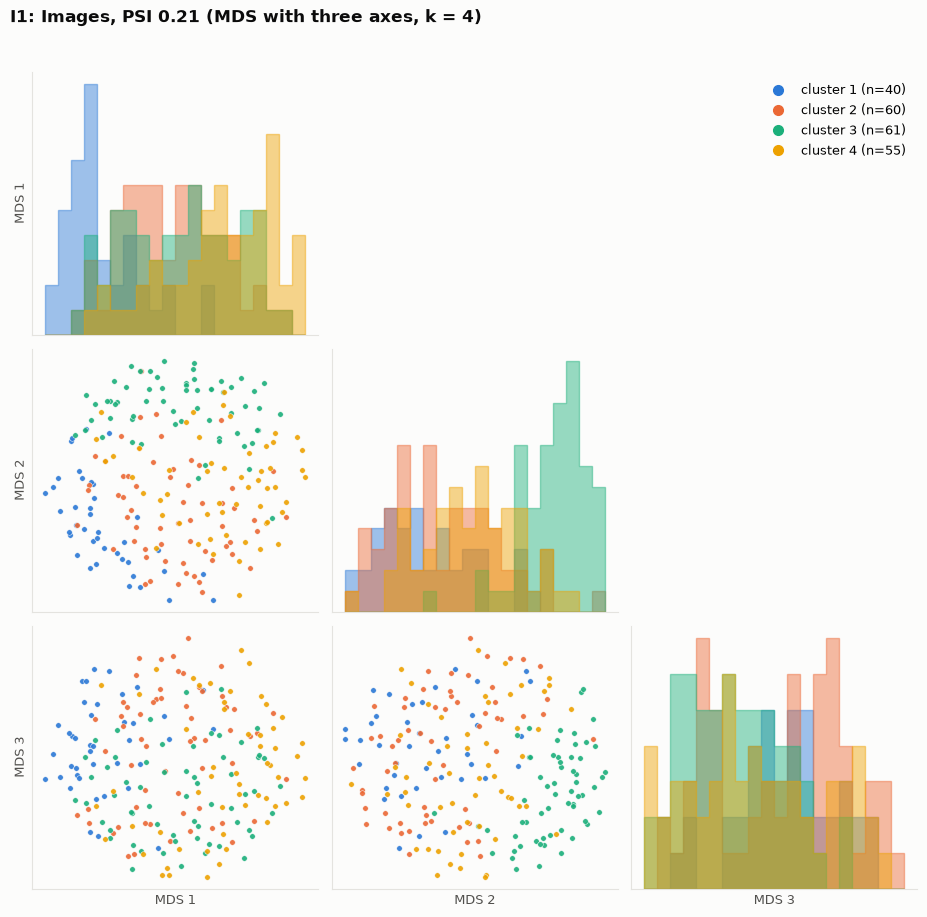

Correlation of each axis with the clinical variables (I1):

,MDS 1,MDS 2,MDS 3
Age,0.440000,-0.160000,0.230000
MMSE,-0.240000,-0.070000,-0.100000
nWBV,-0.610000,0.150000,-0.210000
eTIV,0.570000,-0.060000,0.030000
CDR,0.280000,0.060000,0.190000
Education,0.010000,0.040000,-0.130000
SES,-0.030000,0.000000,0.090000
sex (1 = man),0.420000,0.000000,-0.160000


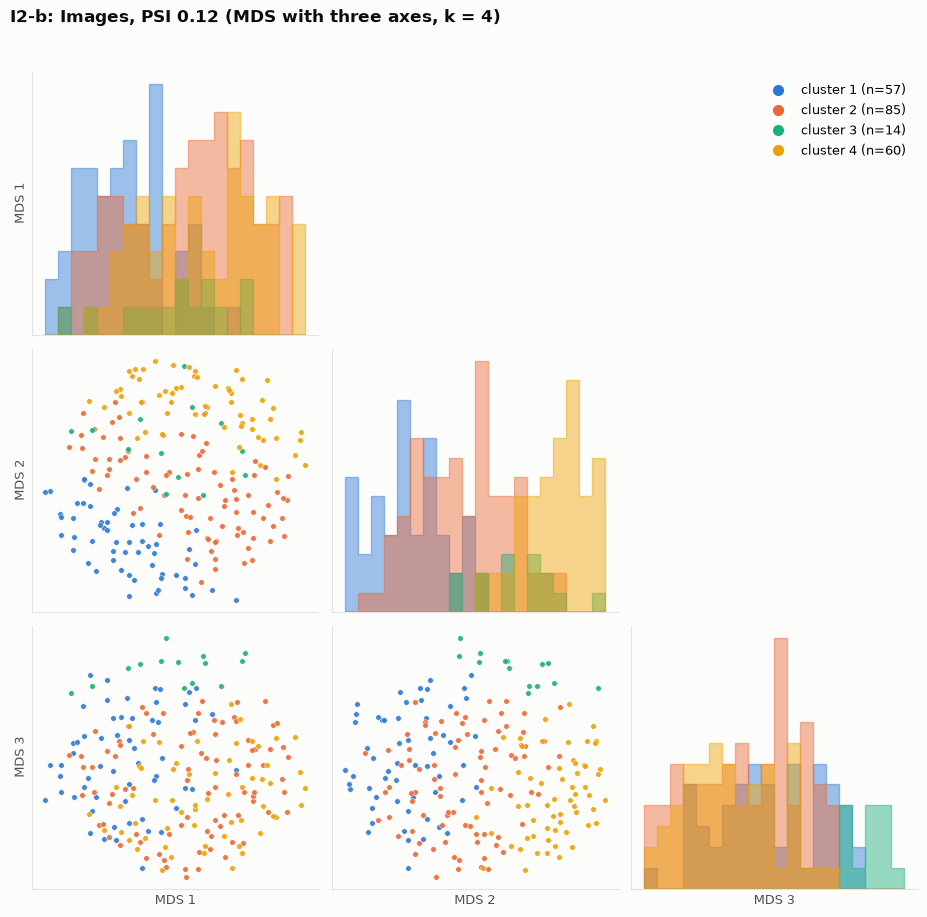

Correlation of each axis with the clinical variables (I2-b):

,MDS 1,MDS 2,MDS 3
Age,0.480000,-0.160000,0.250000
MMSE,-0.260000,-0.050000,-0.090000
nWBV,-0.630000,0.140000,-0.210000
eTIV,0.550000,-0.030000,0.070000
CDR,0.290000,0.050000,0.180000
Education,-0.000000,0.030000,-0.140000
SES,-0.040000,0.000000,0.090000
sex (1 = man),0.440000,0.010000,-0.190000


In [7]:
def mds_stress(D, coords):
    """Kruskal stress-1 between the original distances and the distances on the map."""
    d = squareform(D, checks=False)
    return np.sqrt(((d - pdist(coords)) ** 2).sum() / (d ** 2).sum())

def axis_correlations(coords):
    """Correlation of each map axis with the clinical variables."""
    cols = ["Age", "MMSE", "nWBV", "eTIV", "CDR", "Educ", "SES", cfg.SEX]
    return pd.DataFrame({f"MDS {a + 1}": [np.corrcoef(coords[:, a], df[v])[0, 1] for v in cols]
                         for a in range(coords.shape[1])}, index=["Age", "MMSE", "nWBV", "eTIV", "CDR",
                                                                  "Education", "SES", "sex (1 = man)"])

stress, MAPS_3D = {}, {}
for name in [n for n in ORDER]:
    D = DIST[name]
    xy = MDS(n_components=2, metric="precomputed", init="random", n_init=4, random_state=42).fit_transform(D)
    xyz = MDS(n_components=3, metric="precomputed", init="random", n_init=4, random_state=42).fit_transform(D)
    MAPS_3D[name] = xyz
    stress[name] = {"stress, 2 axes": mds_stress(D, xy), "stress, 3 axes": mds_stress(D, xyz)}
    fig = cluster_scatter_matrix(xyz, labels[name].to_numpy(),
                                 f"{name}: {cfg.CONFIGS[name]['feature_space']}, PSI "
                                 f"{psi.loc['PSI (mean)', name]:.2f} (MDS with three axes, k = {K})")
    fig.savefig(OUT / f"clusters_3d_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    display(Markdown(f"Correlation of each axis with the clinical variables ({name}):"))
    display(axis_correlations(xyz).round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

How well the two- and three-axis maps represent the real distances:

In [8]:
pd.DataFrame(stress).T.round(3)

,"stress, 2 axes","stress, 3 axes"
C1-b,0.228,0.150
C1,0.294,0.207
M2,0.364,0.277
M1,0.414,0.325
C2,0.299,0.213
M3,0.368,0.281
I2,0.379,0.295
I1,0.384,0.298
I2-b,0.370,0.285


**What the third axis adds**

- The third axis makes every map more faithful: the stress falls by about 0.09 in every configuration (C1: 0.29 →
  0.21), so part of what looked like overlap in two dimensions was only the flattening of the map.
- C1: the third axis follows brain volume and cognition (nWBV −0.67, MMSE −0.46, CDR +0.46). In the MDS 1–MDS 3
  panel the younger healthy cluster (1) sits at the bottom and the impaired cluster (4) at the top; in two dimensions
  these clusters overlapped.
- C2: the first axis is cognition with Education/SES (MMSE +0.52, Education +0.84) and the third is sex and head size
  (sex +0.84, eTIV +0.77).
- M2 and M3: the third axis follows age and cognition (Age +0.62, MMSE −0.60 in M2), but the clusters still overlap
  much more than in the clinical configurations.
- M1, I1, I2 and I2-b: only one axis is related to the clinical variables (brain atrophy and head size, |r| ≈ 0.5–0.6
  for nWBV and eTIV in the image configurations); the second and third axes are not related to any clinical variable
  (|r| ≤ 0.36), and the clusters overlap on every pair of axes.

## 8. Cluster profiles of every configuration

Top: Age, MMSE, nWBV and eTIV by cluster (box = interquartile range, line = median, diamond = mean).
Bottom: share of each CDR, Education, SES and sex category within each cluster.

**C1-b**: Clinical, aggregate PSI 0.497

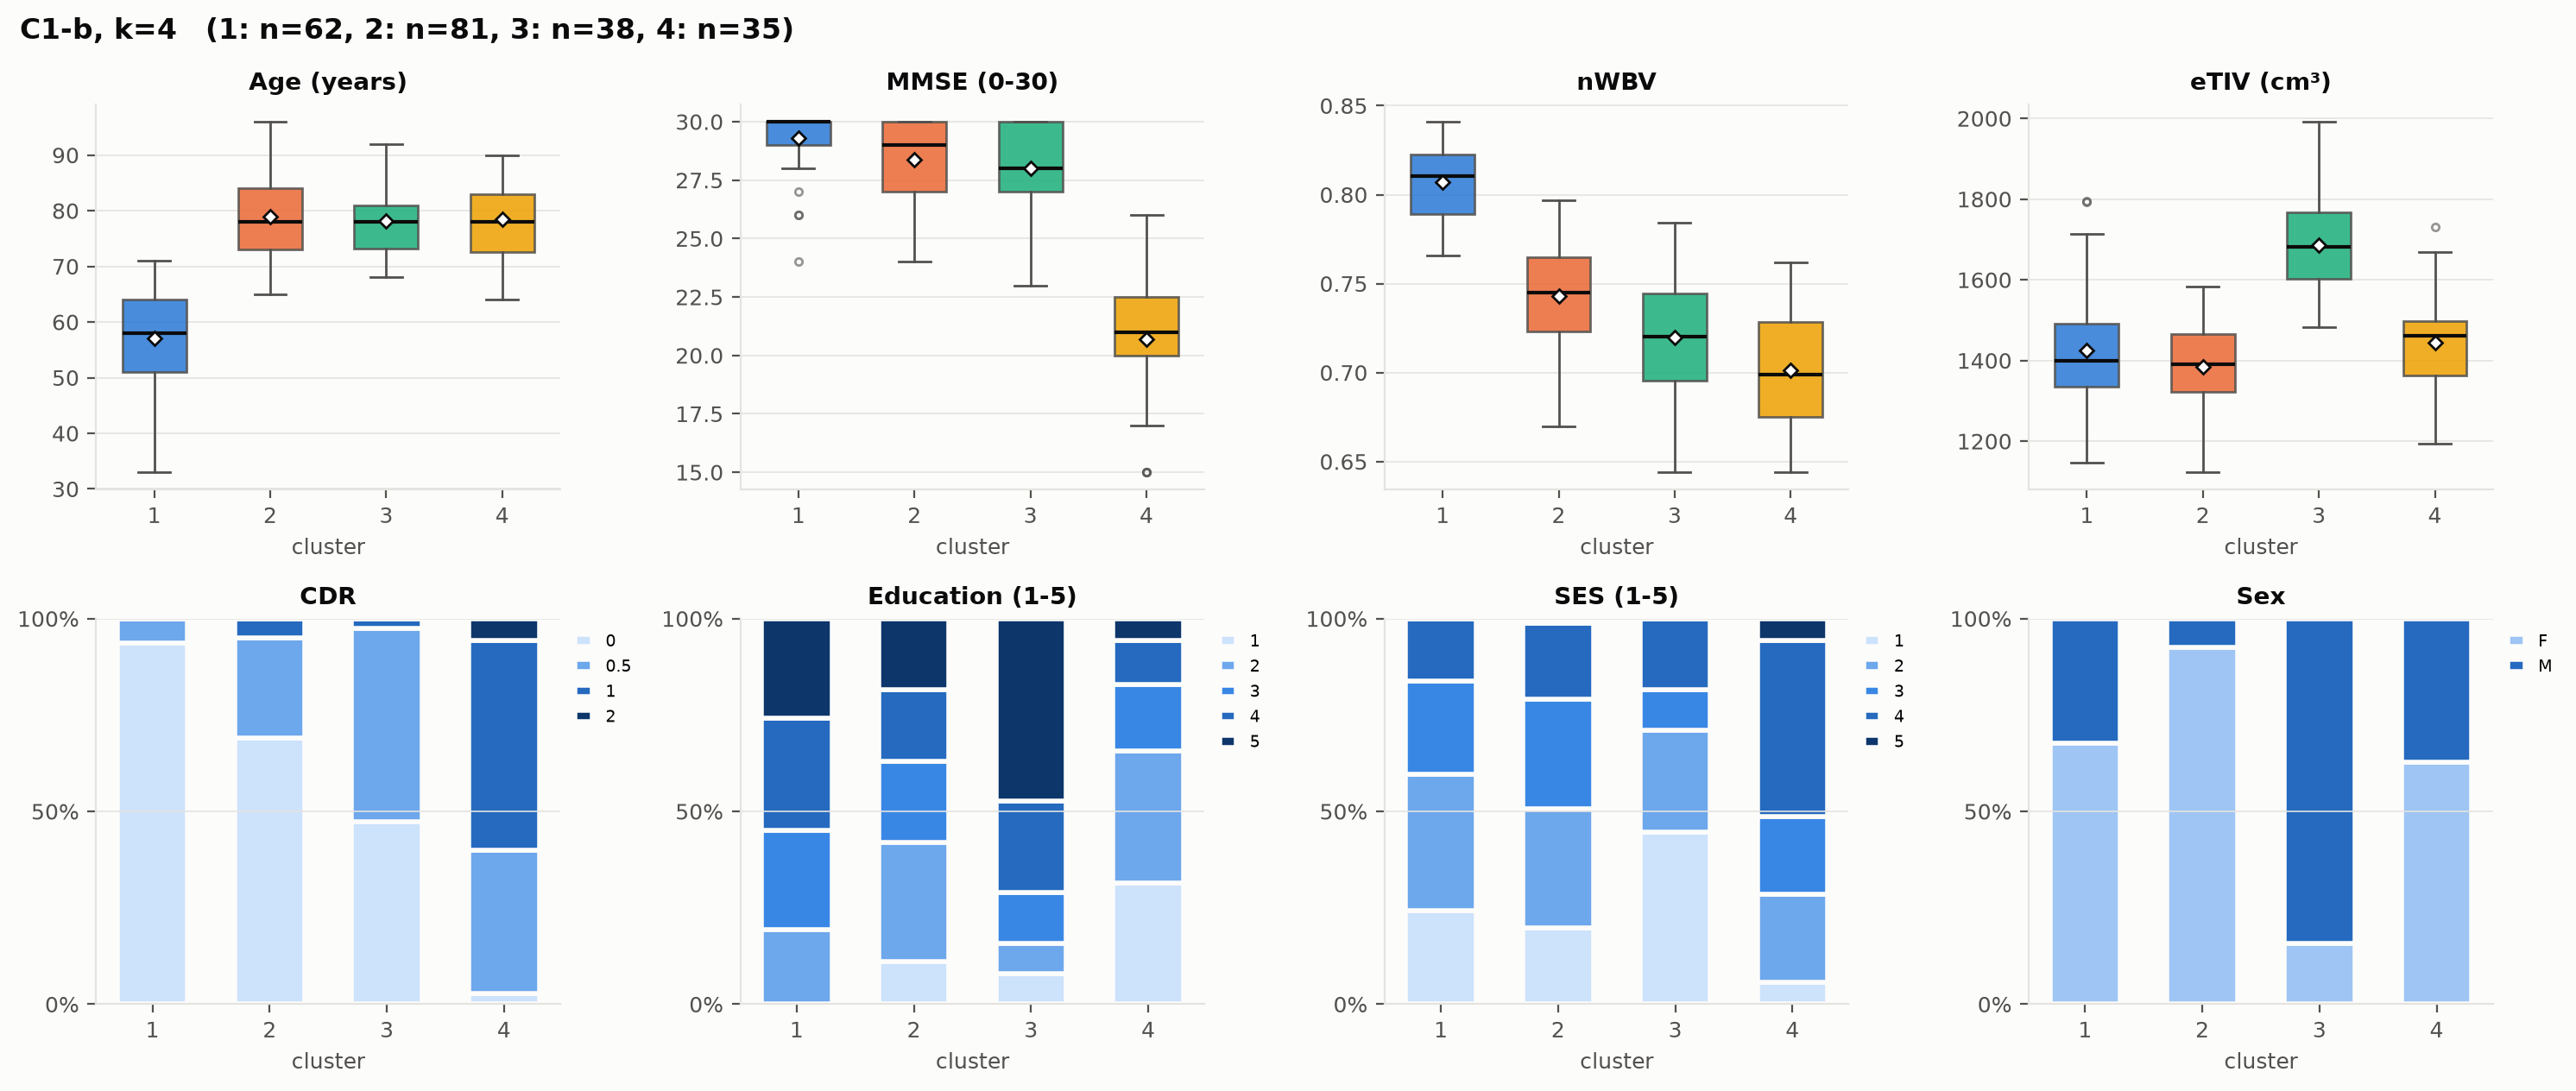

**C1**: Clinical, aggregate PSI 0.434

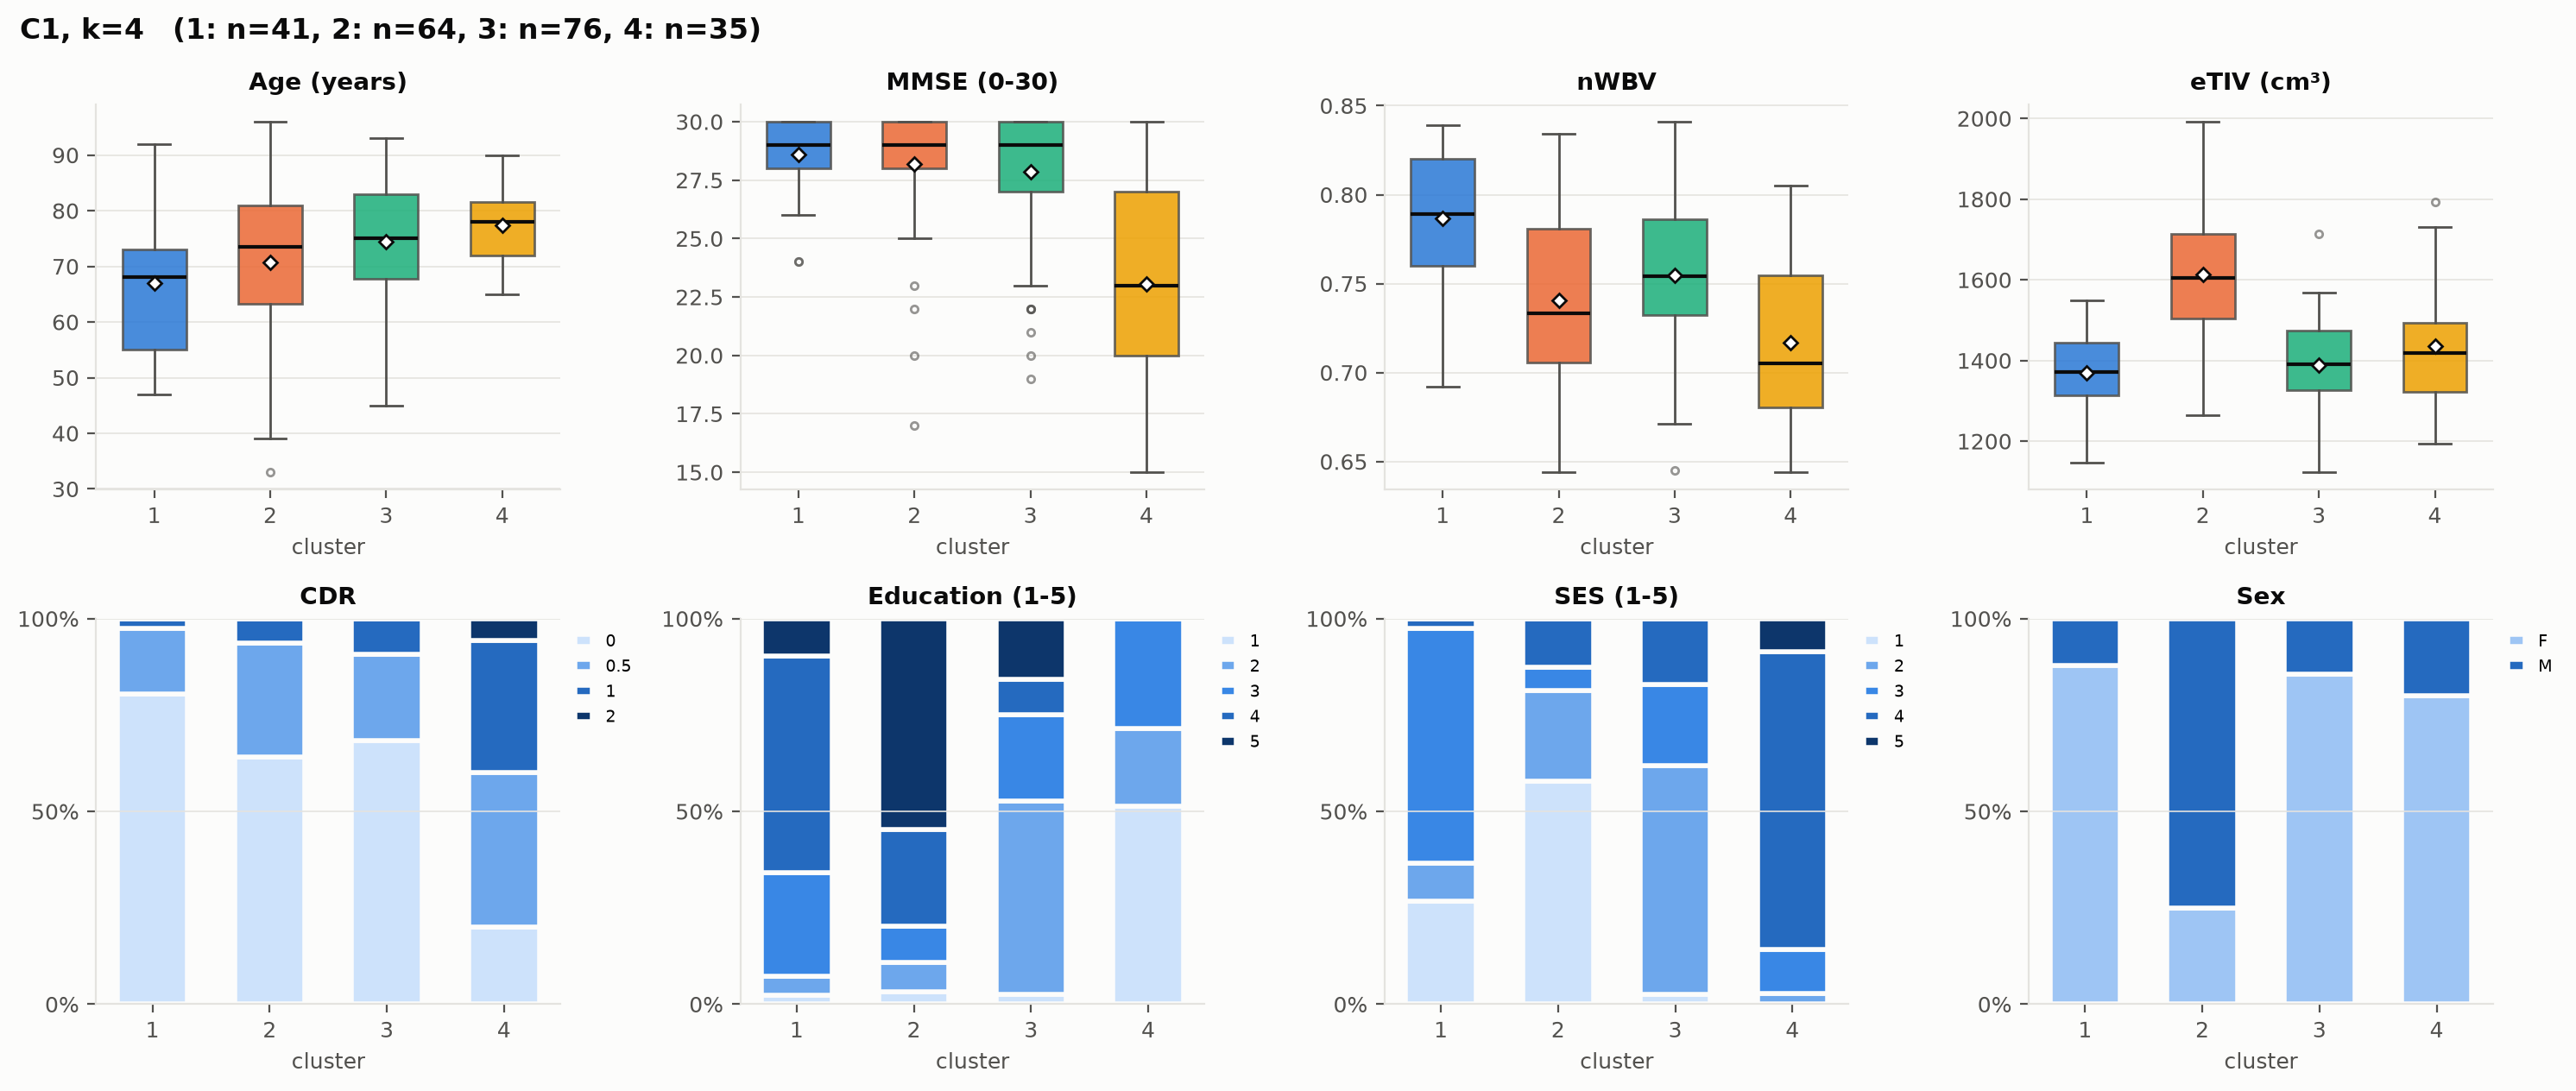

**M2**: Images + clinical, aggregate PSI 0.400

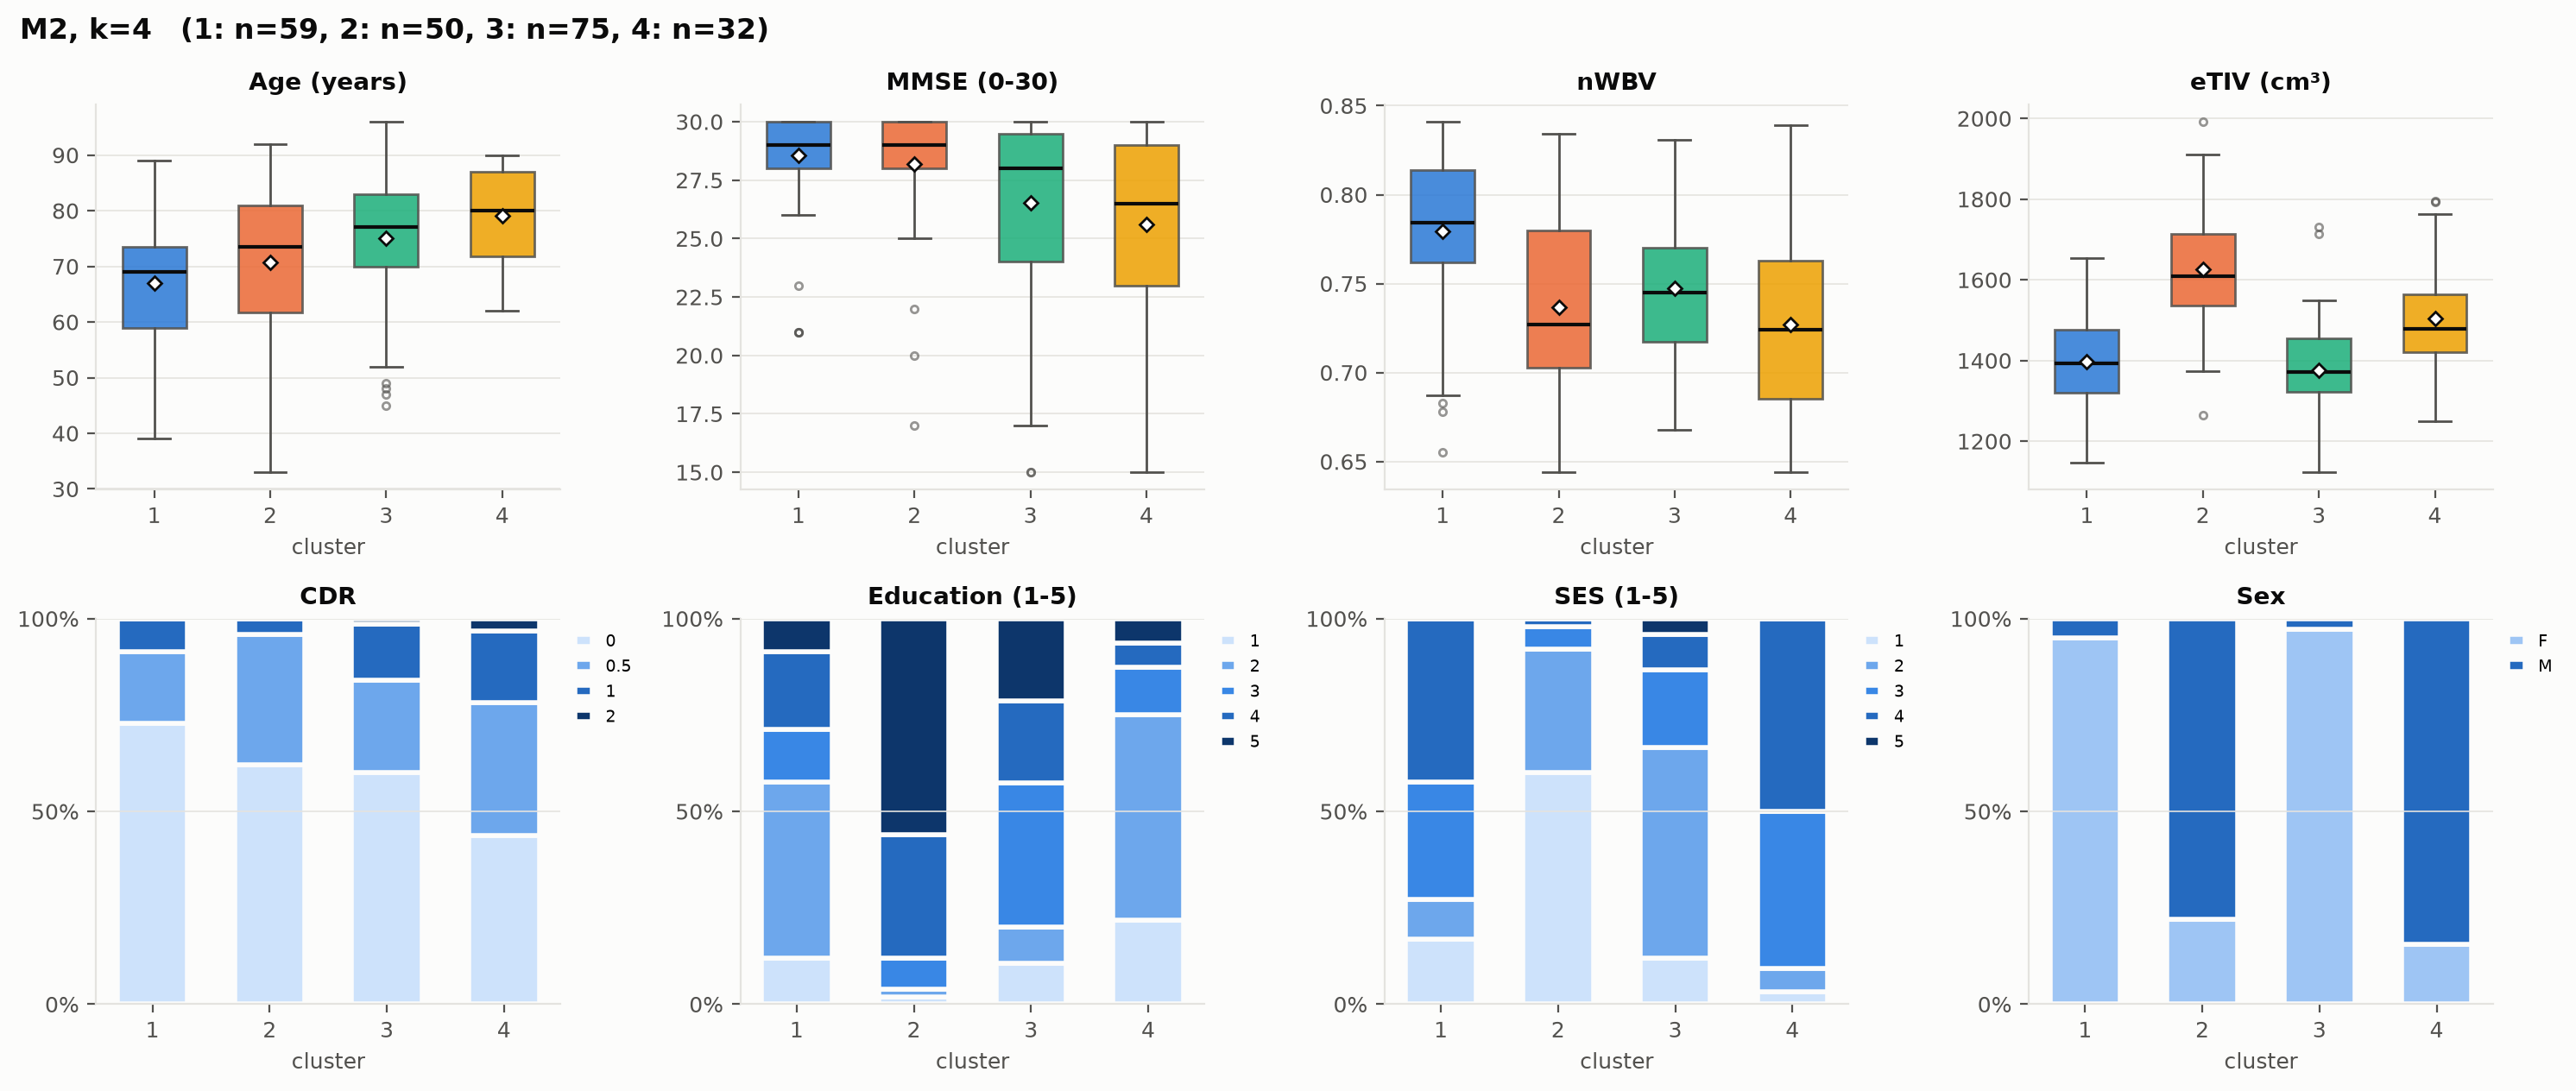

**M1**: Images + clinical, aggregate PSI 0.399

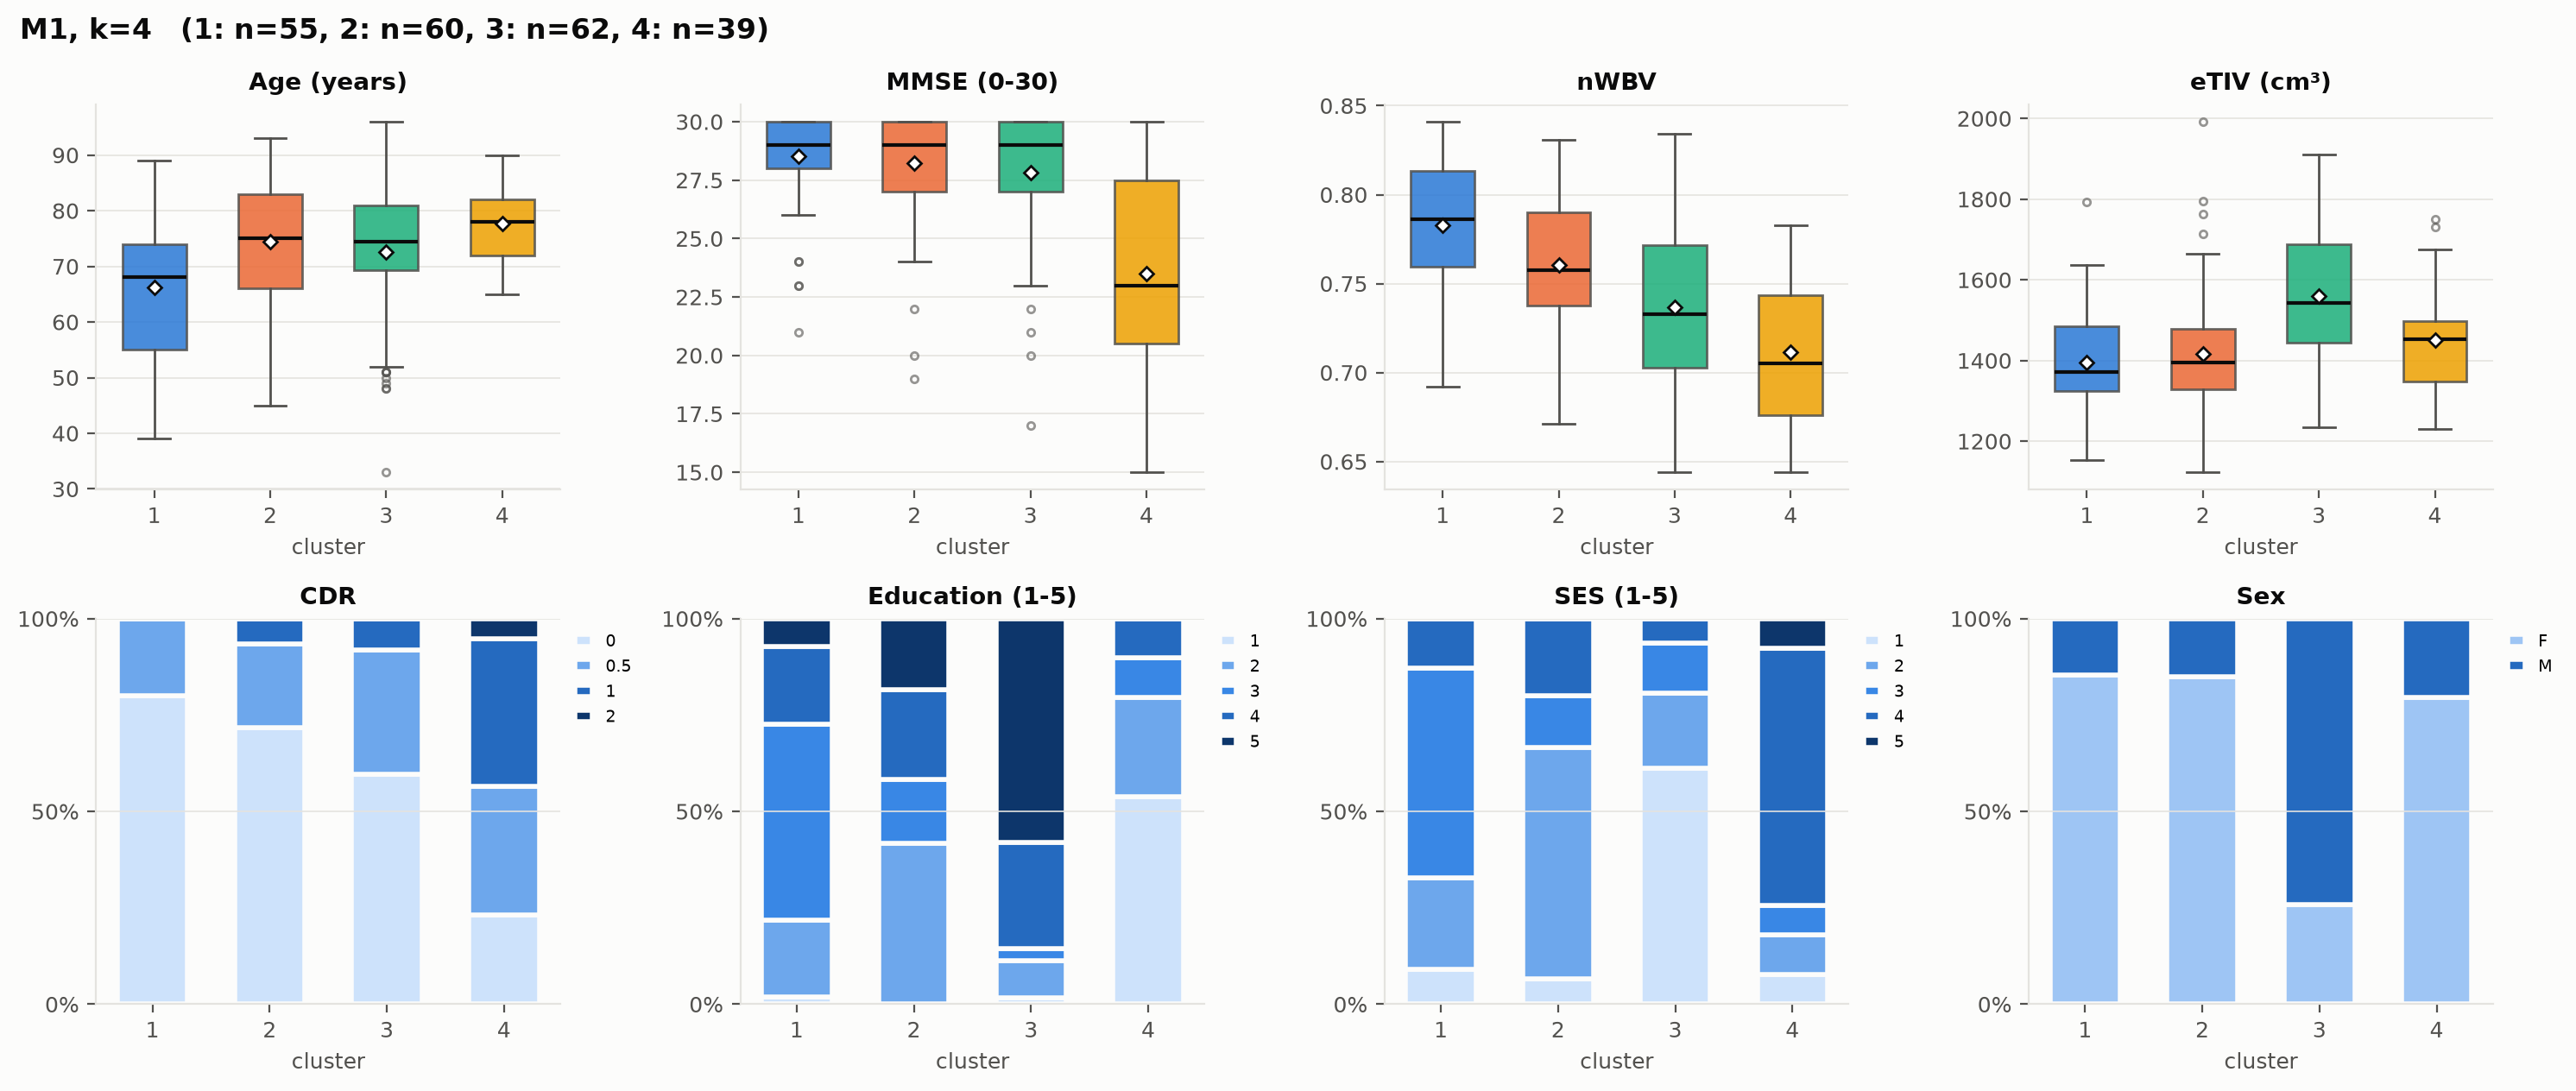

**C2**: Clinical + CDR, aggregate PSI 0.367

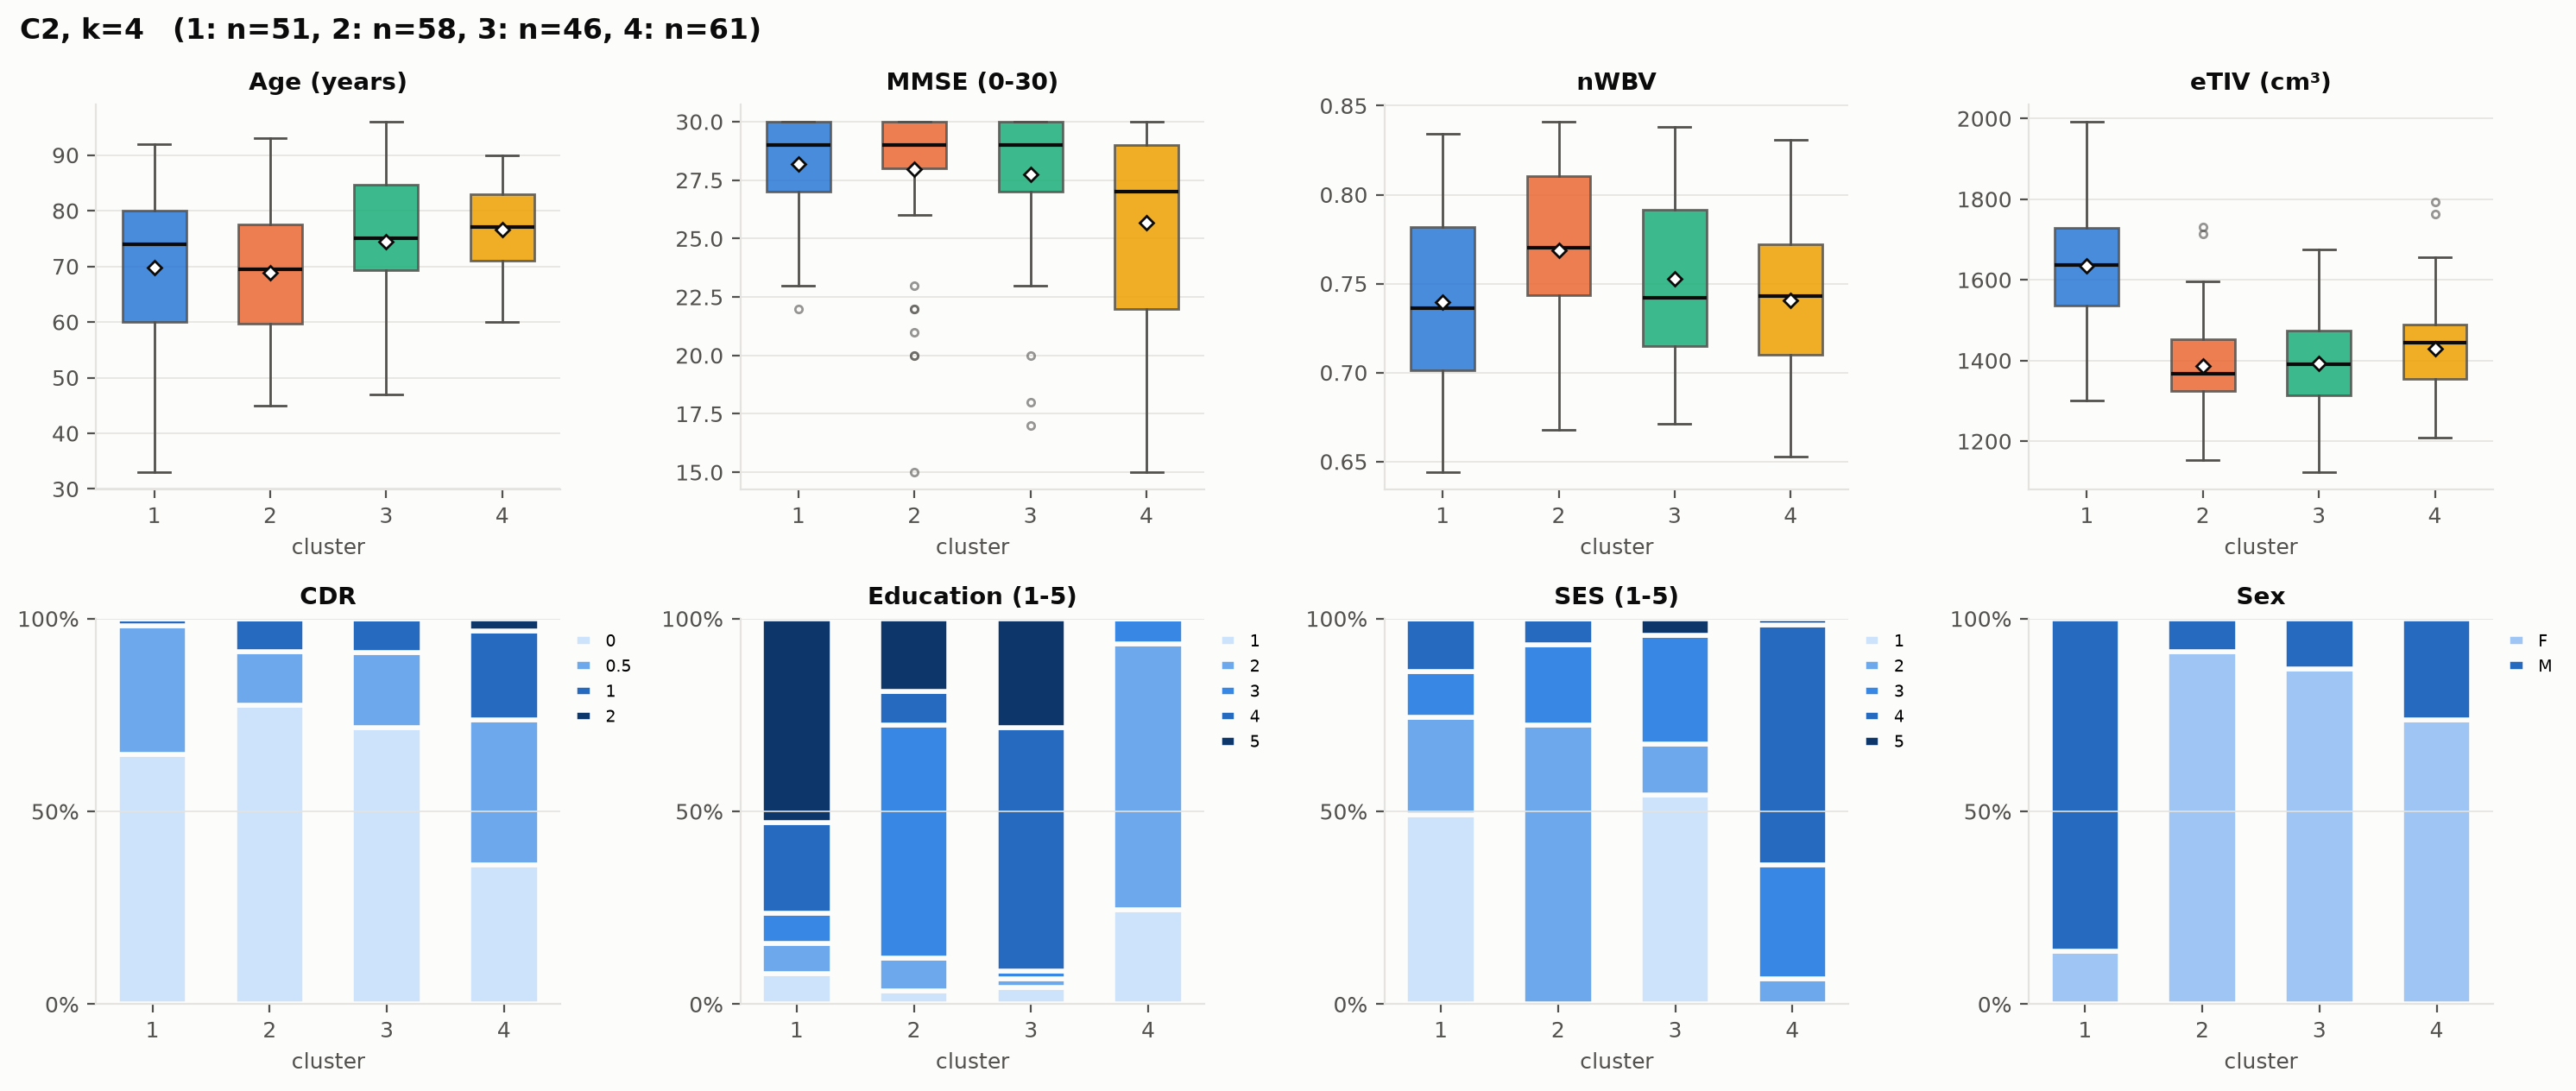

**M3**: Images + clinical + CDR, aggregate PSI 0.350

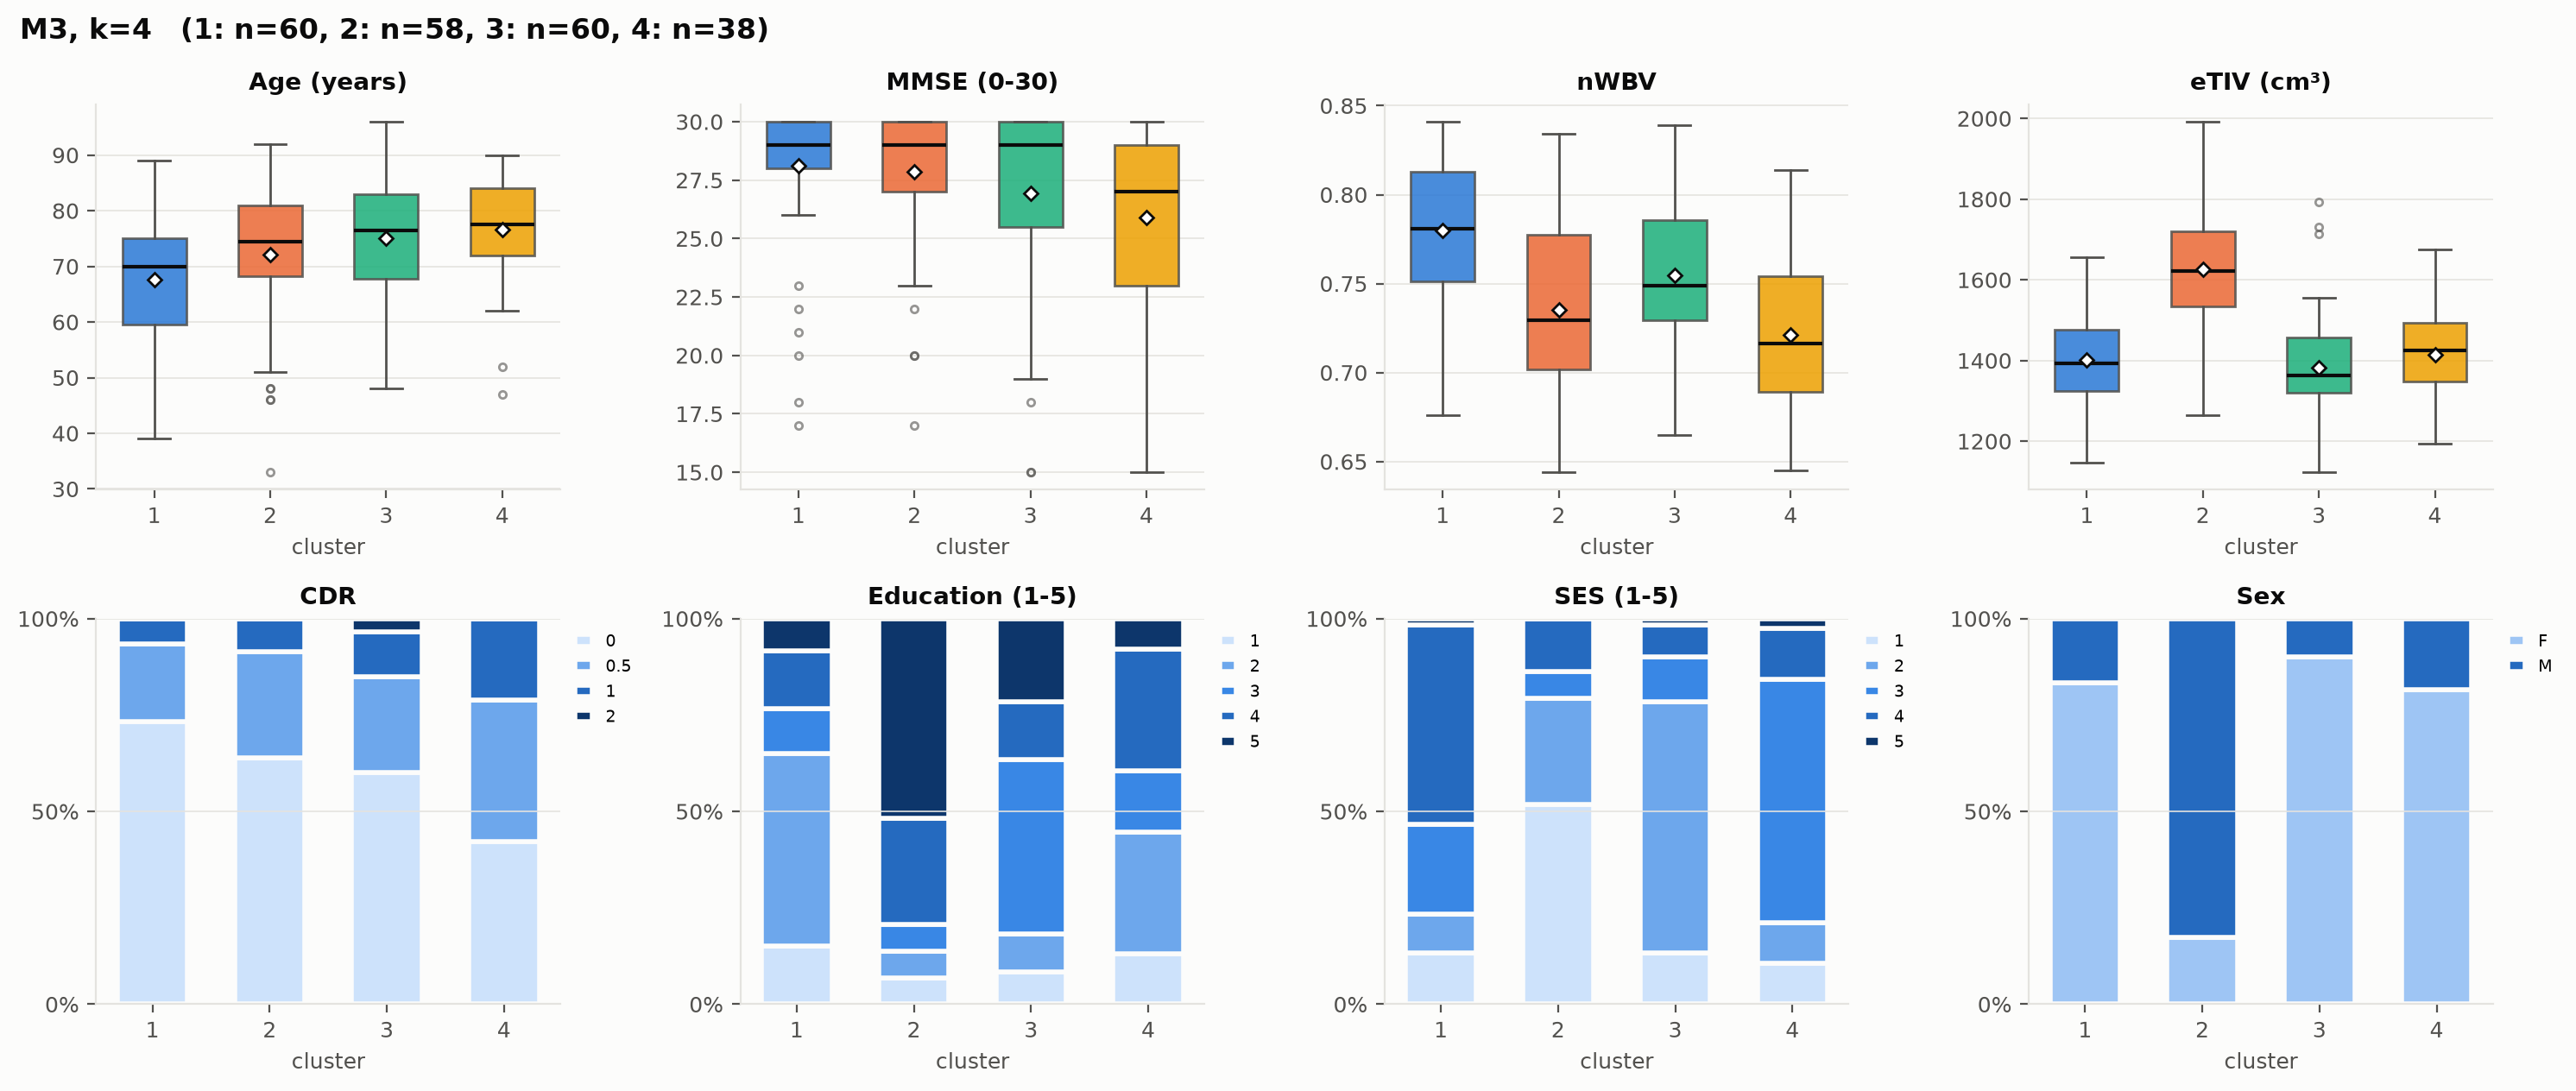

**I2**: Images, aggregate PSI 0.218

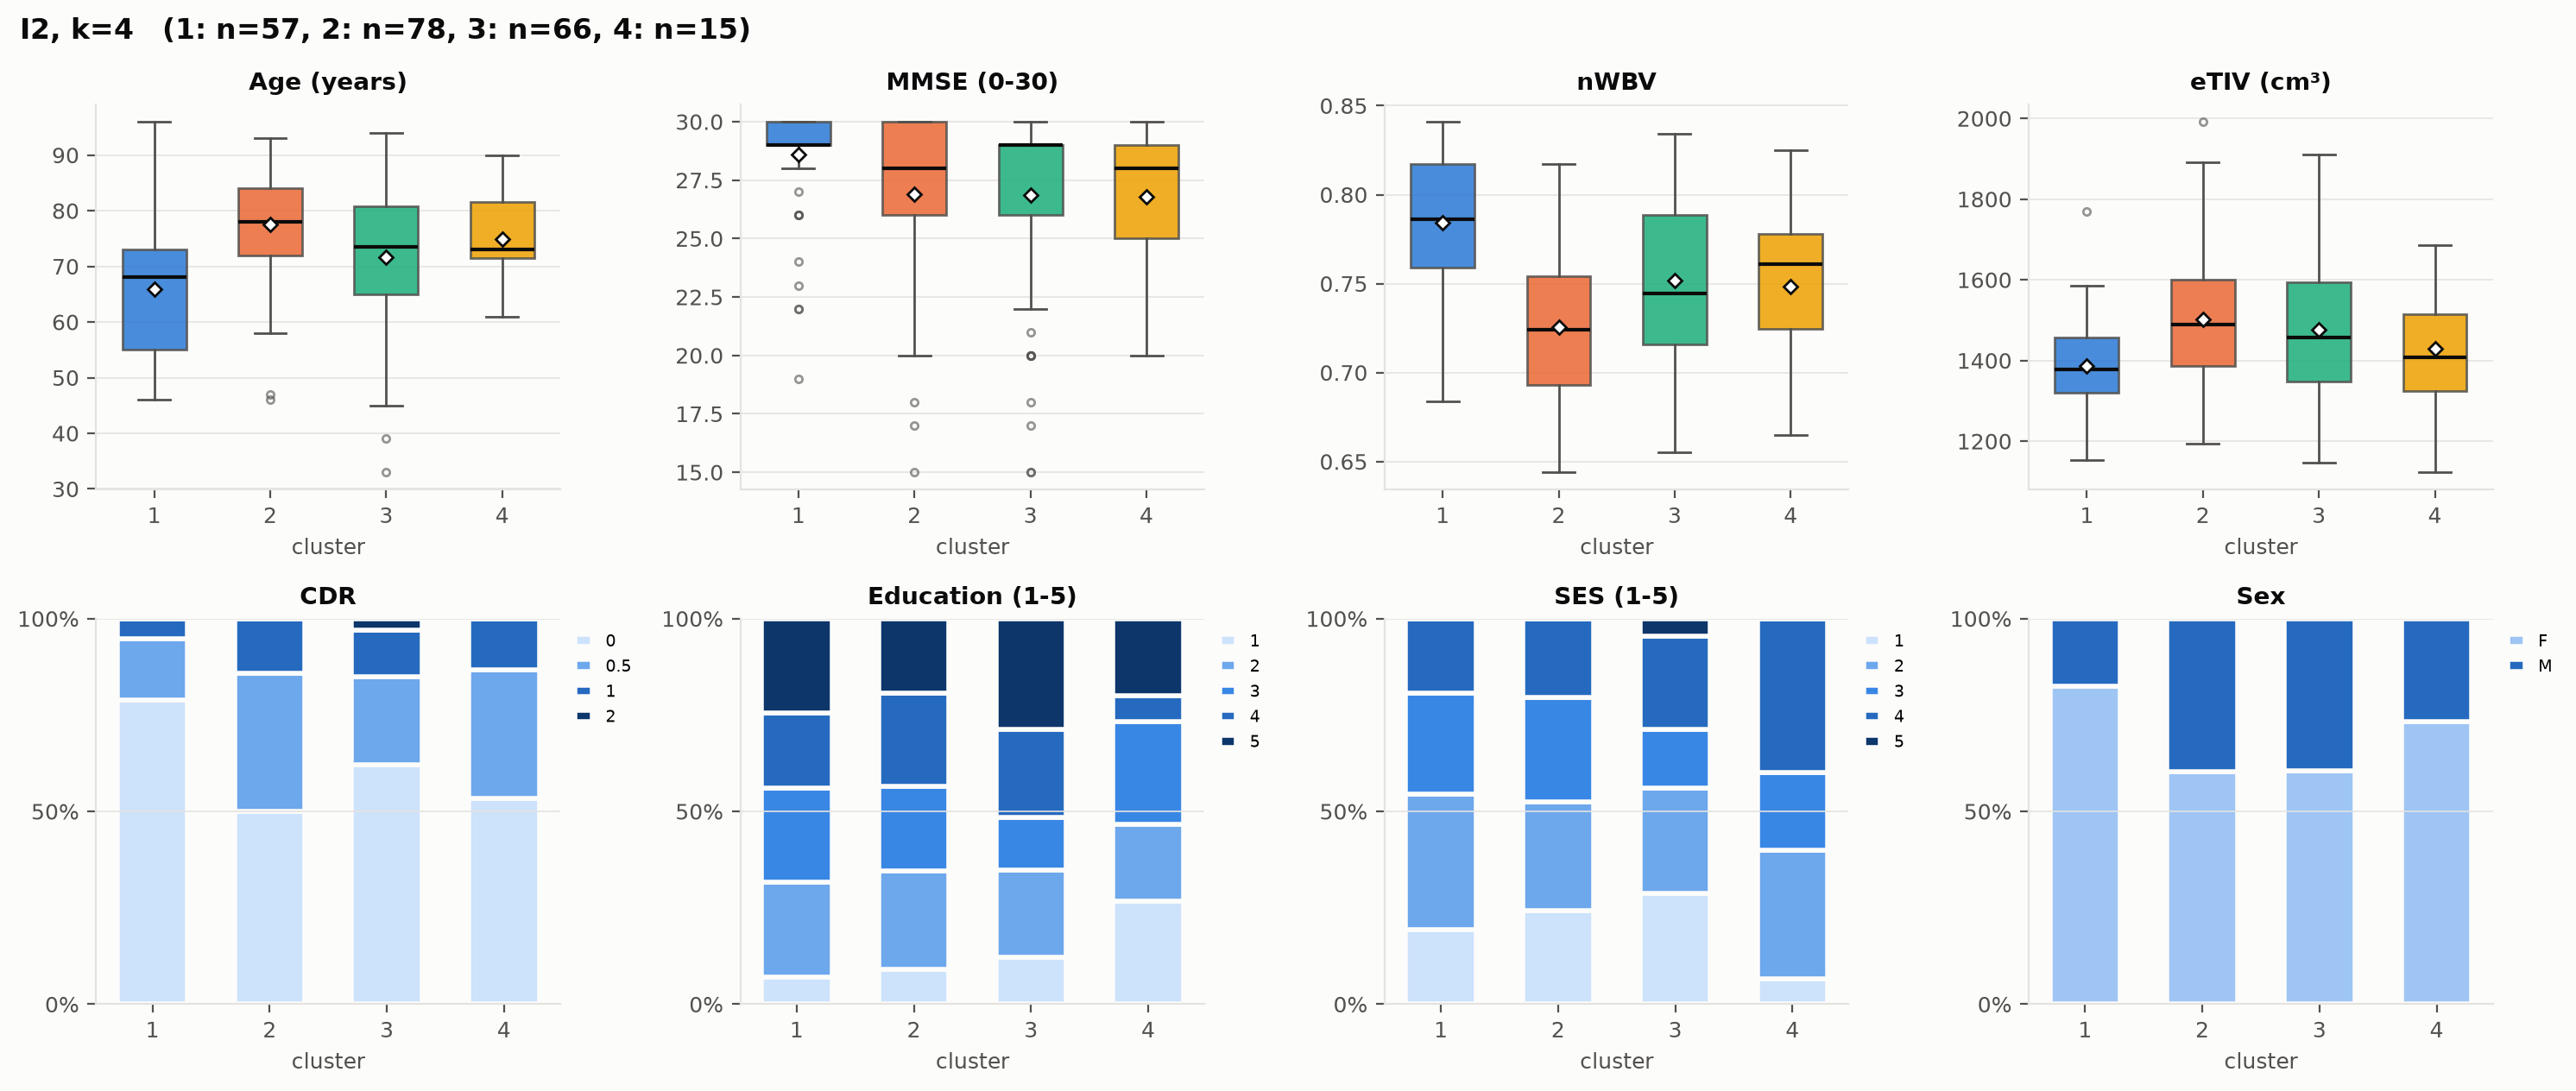

**I1**: Images, aggregate PSI 0.213

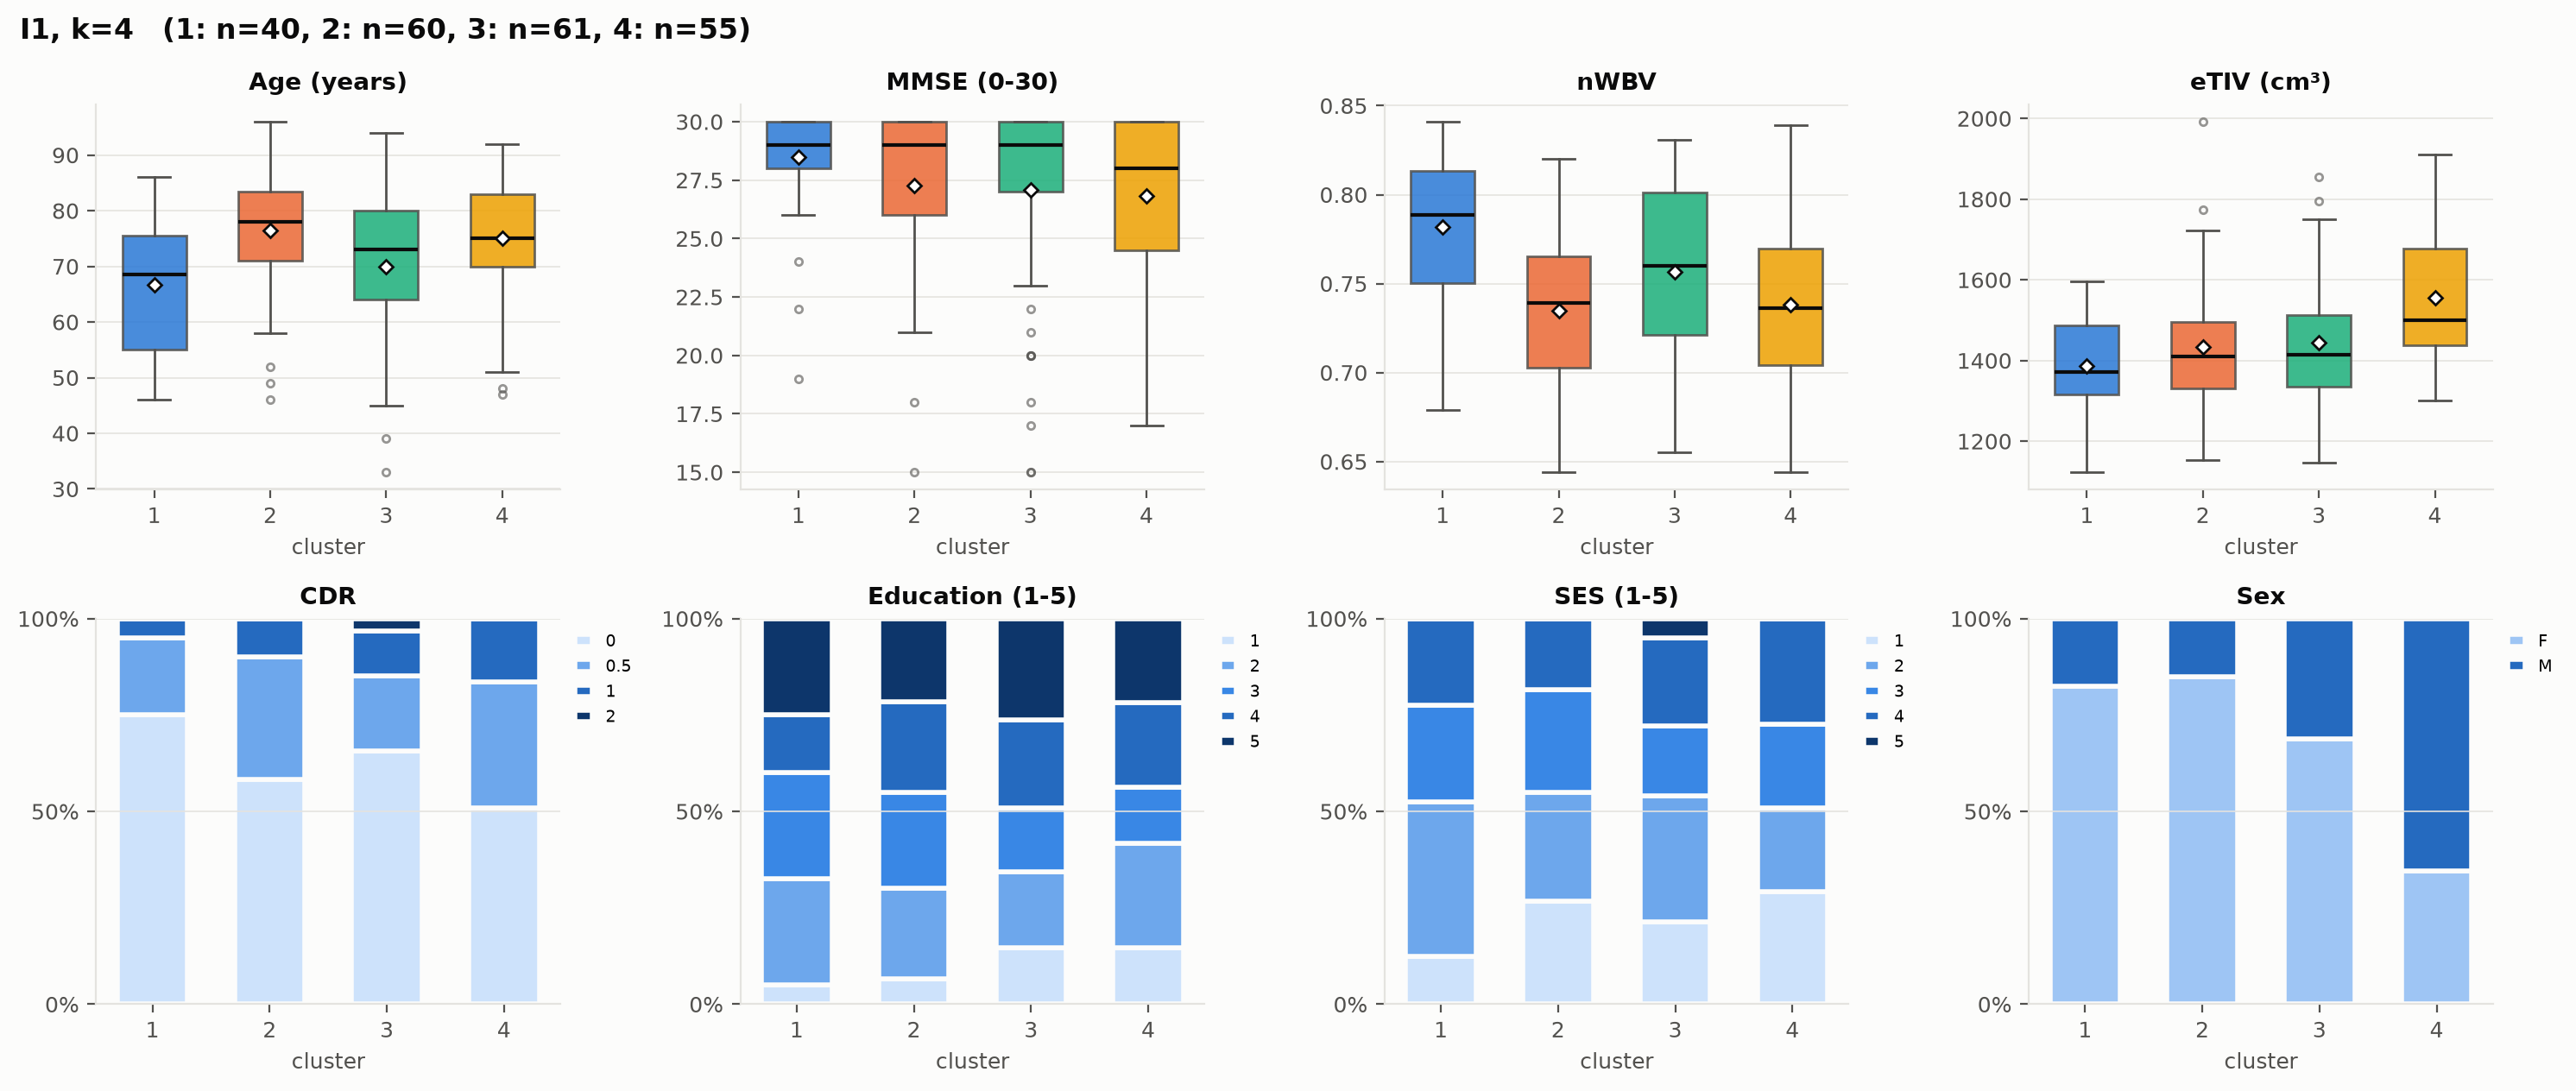

**I2-b**: Images, aggregate PSI 0.119

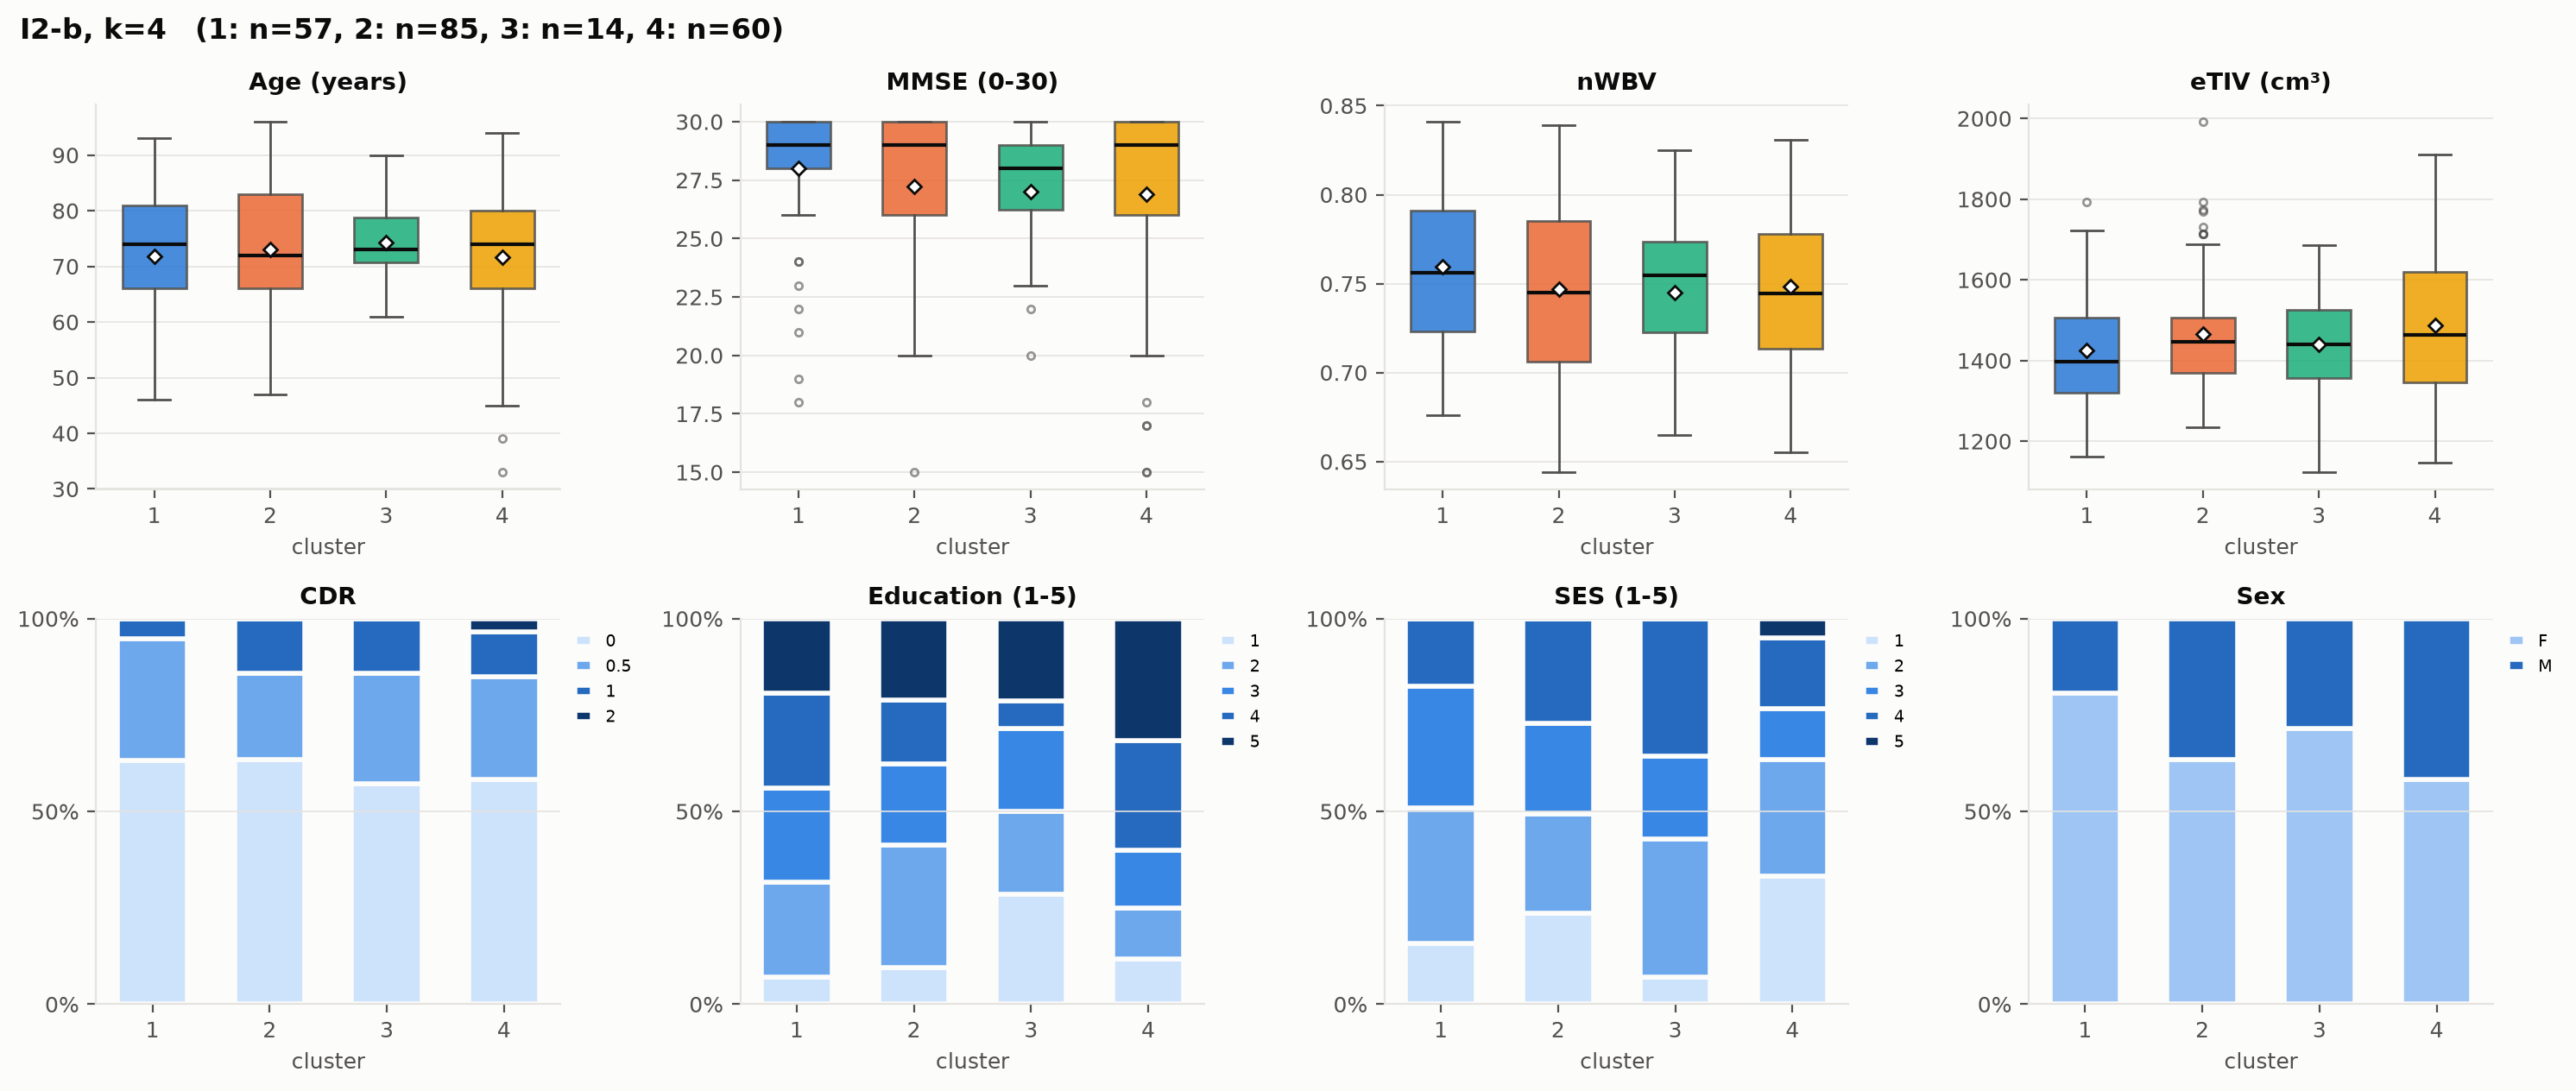

In [9]:
for name in ORDER:
    display(Markdown(f"**{name}**: {cfg.CONFIGS[name]['feature_space']}, aggregate PSI {psi.loc['PSI (mean)', name]:.3f}"))
    show_png(R / "02_compare_configurations" / f"profile_{name}.png")

## 9. Selected configuration

Median [interquartile range] by cluster and the separation of every pair of clusters on every variable.
k-means centroids are not real patients, so each cluster is represented by the patient closest to its centroid.

| Cluster | Label |
|---|---|
| 1 | younger, cognitively healthy |
| 2 | older, healthy, mostly women |
| 3 | older men with large heads, very mild impairment |
| 4 | cognitively impaired |

,Cluster 1,Cluster 2,Cluster 3,Cluster 4
n (%),62 (29%),81 (38%),38 (18%),35 (16%)
Age,"58 [51, 64]","78 [73, 84]","78 [73, 81]","78 [72, 83]"
MMSE,"30 [29, 30]","29 [27, 30]","28 [27, 30]","21 [20, 22]"
nWBV,"0.810 [0.789, 0.823]","0.745 [0.723, 0.765]","0.720 [0.696, 0.744]","0.699 [0.675, 0.728]"
eTIV (cm³),"1398 [1334, 1490]","1390 [1322, 1465]","1682 [1602, 1767]","1461 [1363, 1497]"
Education (1-5),"4 [3, 5]","3 [2, 4]","4 [3, 5]","2 [1, 3]"
SES (1-5),"2 [2, 3]","2 [2, 3]","2 [1, 3]","4 [2, 4]"
CDR 0 / 0.5 / 1 / 2 (%),94 / 6 / 0 / 0,69 / 26 / 5 / 0,47 / 50 / 3 / 0,3 / 37 / 54 / 6
Men (%),32,7,84,37


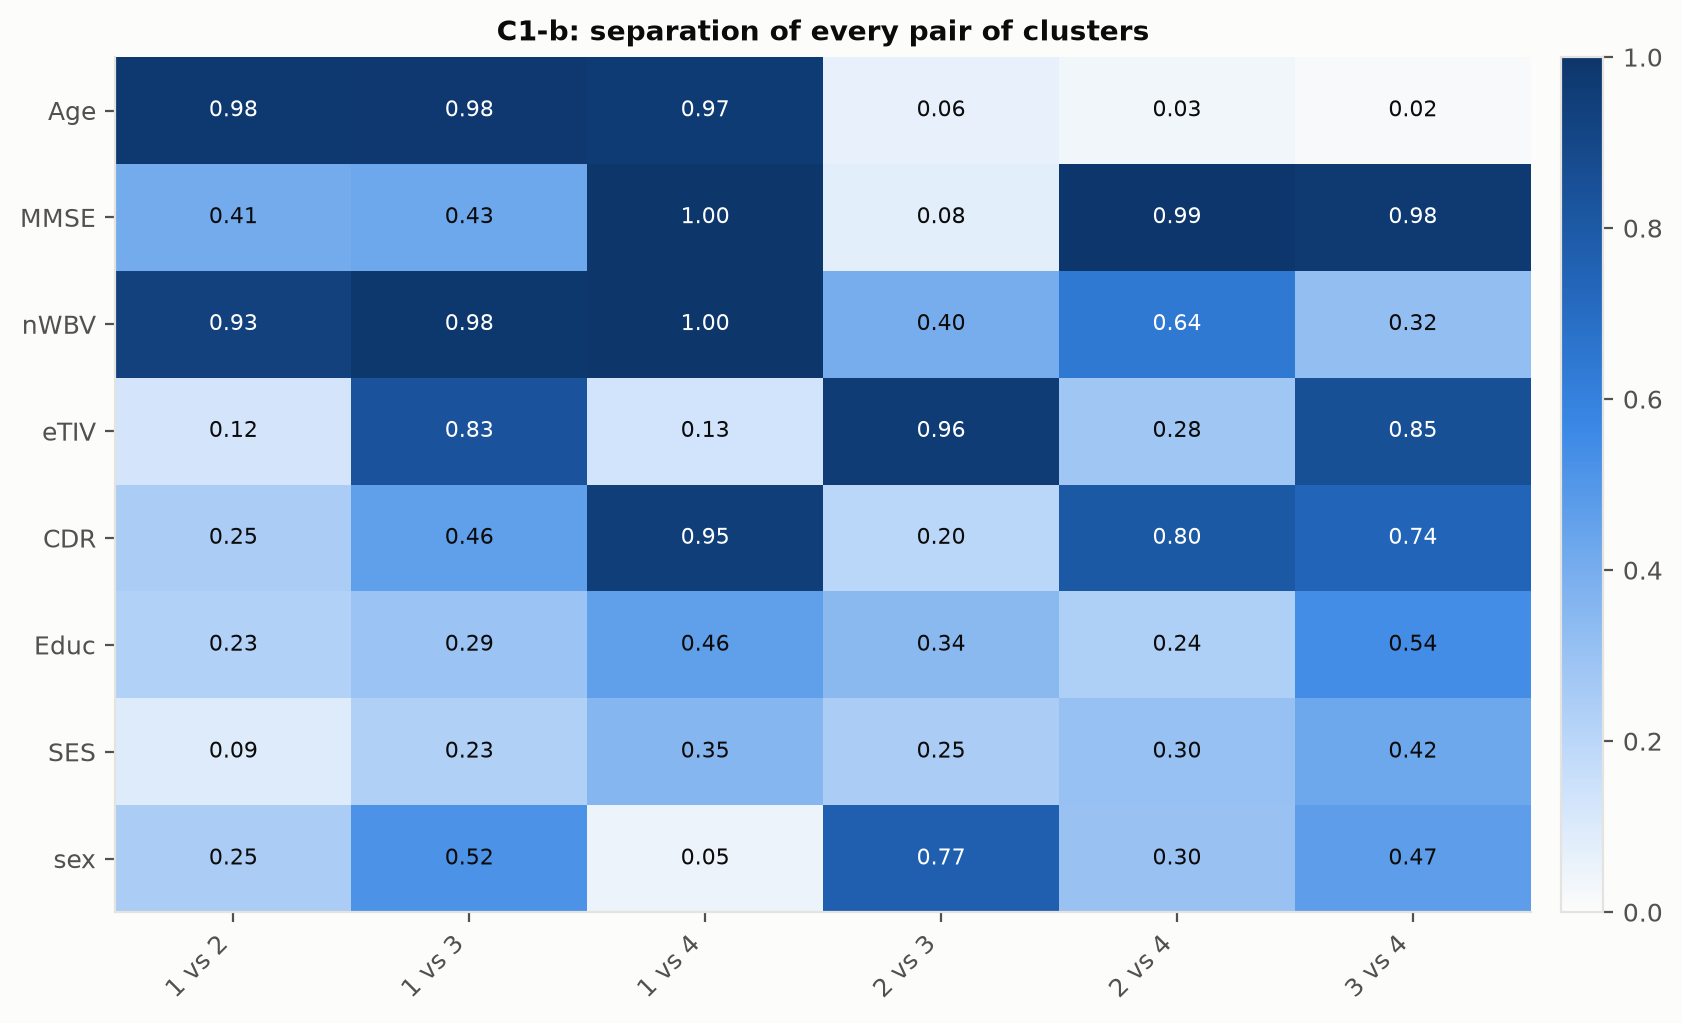

**Representative patients**

,cluster,role,patient,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,representative,OAS1_0378,F,58,30.0,0.0,0.821,1418,2.0,2.0
1,1,neighbour 1,OAS1_0357,F,55,30.0,0.0,0.820,1450,4.0,3.0
2,1,neighbour 2,OAS1_0345,F,54,30.0,0.0,0.831,1389,4.0,2.0
3,2,representative,OAS1_0001,F,74,29.0,0.0,0.743,1344,2.0,3.0
4,2,neighbour 1,OAS1_0244,F,80,29.0,0.0,0.737,1341,4.0,2.0
5,2,neighbour 2,OAS1_0161,F,84,27.0,0.5,0.727,1390,2.0,2.0
6,3,representative,OAS1_0441,M,81,29.0,0.5,0.721,1647,5.0,1.0
7,3,neighbour 1,OAS1_0186,M,84,29.0,0.0,0.731,1707,5.0,1.0
8,3,neighbour 2,OAS1_0418,M,74,28.0,0.5,0.747,1659,5.0,2.0
9,4,representative,OAS1_0233,F,77,20.0,0.5,0.701,1376,1.0,4.0


In [10]:
sel = selection["selected"]
display(pd.read_csv(R / "03_profile_selected" / f"profile_table_{sel}.csv", index_col=0))
show_png(R / "03_profile_selected" / f"pairwise_{sel}.png", 800)
display(Markdown("**Representative patients**"))
display(pd.read_csv(R / "03_profile_selected" / f"representatives_{sel}.csv"))

## 10. Stability

30 bootstrap resamples of the 216 patients; on each, the configuration is refitted and all 216 patients are
assigned to the nearest medoid or centroid. The Adjusted Rand Index is computed between every pair of the 30
partitions (435 pairs). Cross-check: 30 subsamples of 80% without replacement. RelMS configurations are left out
because new patients are assigned with the G-Gower point distance.

,pairs,mean,SD,median,min,max,mean ARI vs full-data partition,80% subsamples (mean)
configuration,,,,,,,,
C1-b,435,0.749,0.109,0.744,0.451,0.964,0.816,0.845
C1,435,0.336,0.129,0.314,0.115,0.868,0.366,0.433
C2,435,0.371,0.117,0.359,0.127,0.930,0.393,0.432
I2,435,0.155,0.096,0.146,-0.045,0.681,0.204,0.408
I2-b,435,0.489,0.131,0.479,0.150,0.880,0.559,0.589
M2,435,0.202,0.095,0.185,0.042,0.574,0.264,0.514
M3,435,0.197,0.091,0.180,0.050,0.618,0.239,0.453


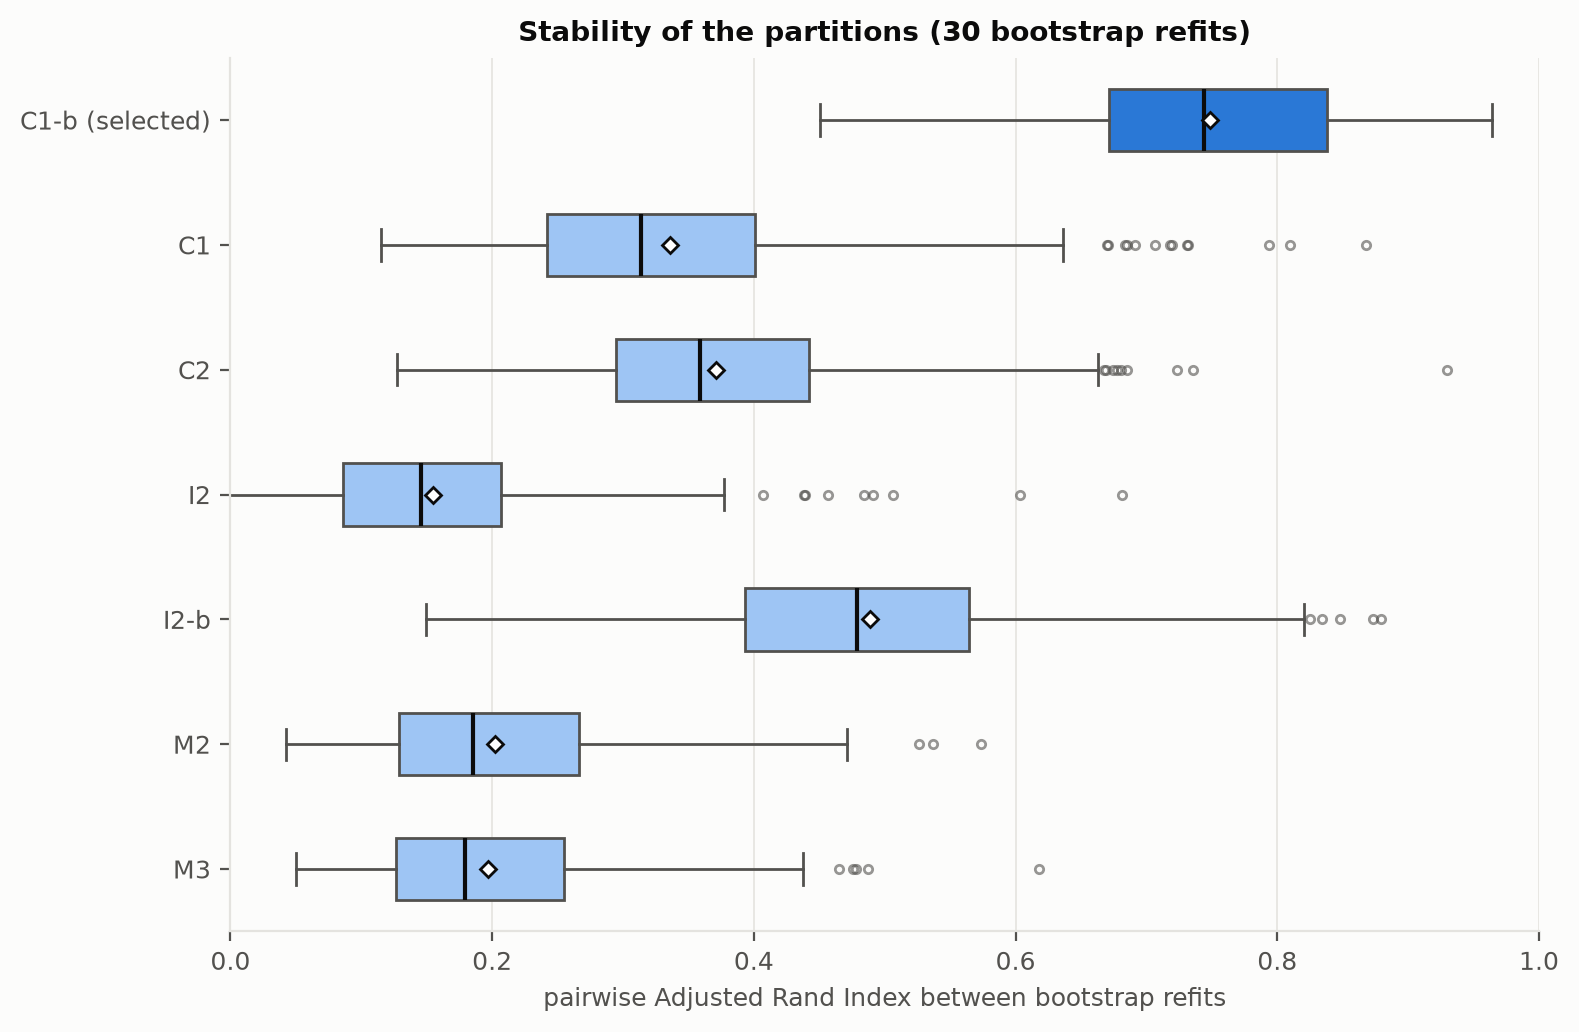

In [11]:
st = pd.read_csv(R / "04_stability" / "stability_summary.csv", index_col=0)
sub = pd.read_csv(R / "04_stability" / "stability_subsampling80.csv", index_col=0)
st["80% subsamples (mean)"] = sub["mean"]
display(st.round(3))
show_png(R / "04_stability" / "stability_boxplot.png", 750)

## 11. Robustness checks and secondary results

Number of image components: PCA refitted on the 216 patients for τ = 0.50, 0.592 and 0.90, and every image
configuration refitted. Aggregate PSI:

In [12]:
t = pd.read_csv(R / "06_pca_robustness" / "aggregate_psi_by_tau.csv", index_col=0)
t.columns = ["main (416 patients, 110 PCs)", "τ = 0.50 (55 PCs)", "τ = 0.592 (72 PCs)", "τ = 0.90 (163 PCs)"]
display(t.round(3))

,"main (416 patients, 110 PCs)",τ = 0.50 (55 PCs),τ = 0.592 (72 PCs),τ = 0.90 (163 PCs)
C1,0.434,0.434,0.434,0.434
C1-b,0.497,0.497,0.497,0.497
C2,0.367,0.367,0.367,0.367
I1,0.213,0.221,0.226,0.202
I2,0.218,0.256,0.225,0.231
I2-b,0.119,0.163,0.117,0.114
M1,0.399,0.341,0.389,0.391
M2,0.400,0.406,0.403,0.418
M3,0.350,0.369,0.394,0.404


Number of clusters: aggregate PSI of every configuration for k = 2 to 5:

In [13]:
path = OUT / "psi_all_configurations_by_k.csv"
if not path.exists():
    rows = {}
    for name in cfg.CONFIGS:
        for k in cfg.K_CANDIDATES:
            r = fit_configuration(name, k, df, metric=selection["m3_metric"] if name == "M3" else None)
            rows[(name, f"k = {k}")] = psi_column(df, r["labels"], name)["PSI (mean)"]
    pd.Series(rows).unstack().to_csv(path)
display(pd.read_csv(path, index_col=0).loc[ORDER].round(3))

,k = 2,k = 3,k = 4,k = 5
C1-b,0.455,0.460,0.497,0.528
C1,0.313,0.305,0.434,0.439
M2,0.303,0.344,0.400,0.437
M1,0.312,0.329,0.399,0.403
C2,0.305,0.322,0.367,0.385
M3,0.318,0.321,0.350,0.422
I2,0.293,0.233,0.218,0.270
I1,0.102,0.212,0.213,0.195
I2-b,0.167,0.147,0.119,0.195


Silhouette width in each configuration's own distance (comparable only within a distance family), and agreement with CDR (merged into 0 / 0.5 / ≥ 1 and healthy / impaired; C2 and M3 use CDR as an input):

In [14]:
display(pd.read_csv(R / "05_secondary_results" / "silhouette_by_family.csv", index_col=[0, 1]))
display(pd.read_csv(R / "05_secondary_results" / "agreement_with_cdr.csv", index_col=0).round(3))

feature space  silhouette
distance family     configuration                                     
Euclidean (k-means) C1-b                          Clinical       0.199
                    I2-b                            Images       0.049
RelMS               I1                              Images       0.020
                    M1                   Images + clinical       0.006
Robust G-Gower      C1                            Clinical       0.102
                    C2                      Clinical + CDR       0.111
                    I2                              Images       0.023
                    M2                   Images + clinical       0.022
                    M3             Images + clinical + CDR       0.024

,CDR is an input,ARI (0 / 0.5 / ≥1),NMI (0 / 0.5 / ≥1),ARI (healthy / impaired),NMI (healthy / impaired)
configuration,,,,,
C1,no,0.060,0.087,0.056,0.078
C1-b,no,0.190,0.258,0.174,0.224
C2,yes,0.035,0.070,0.048,0.057
I1,no,-0.002,0.018,0.003,0.015
I2,no,0.010,0.030,0.019,0.030
I2-b,no,0.000,0.010,-0.002,0.001
M1,no,0.070,0.110,0.065,0.081
M2,no,0.015,0.028,0.012,0.017
M3,yes,0.019,0.023,0.018,0.022


## 12. Comparison with the previous method

The previous method (RelMS on the five image blocks plus an unscaled Euclidean clinical block with ASF; sex,
Education and SES as Hamming), refitted at k = 4 on the same 216 patients, against the selected configuration.

,Age,MMSE,nWBV,eTIV,CDR,Educ,SES,sex,PSI (mean)
previous method,0.033,0.064,0.128,0.652,0.096,0.538,0.554,0.354,0.302
selected (C1-b),0.507,0.646,0.712,0.530,0.566,0.350,0.275,0.392,0.497


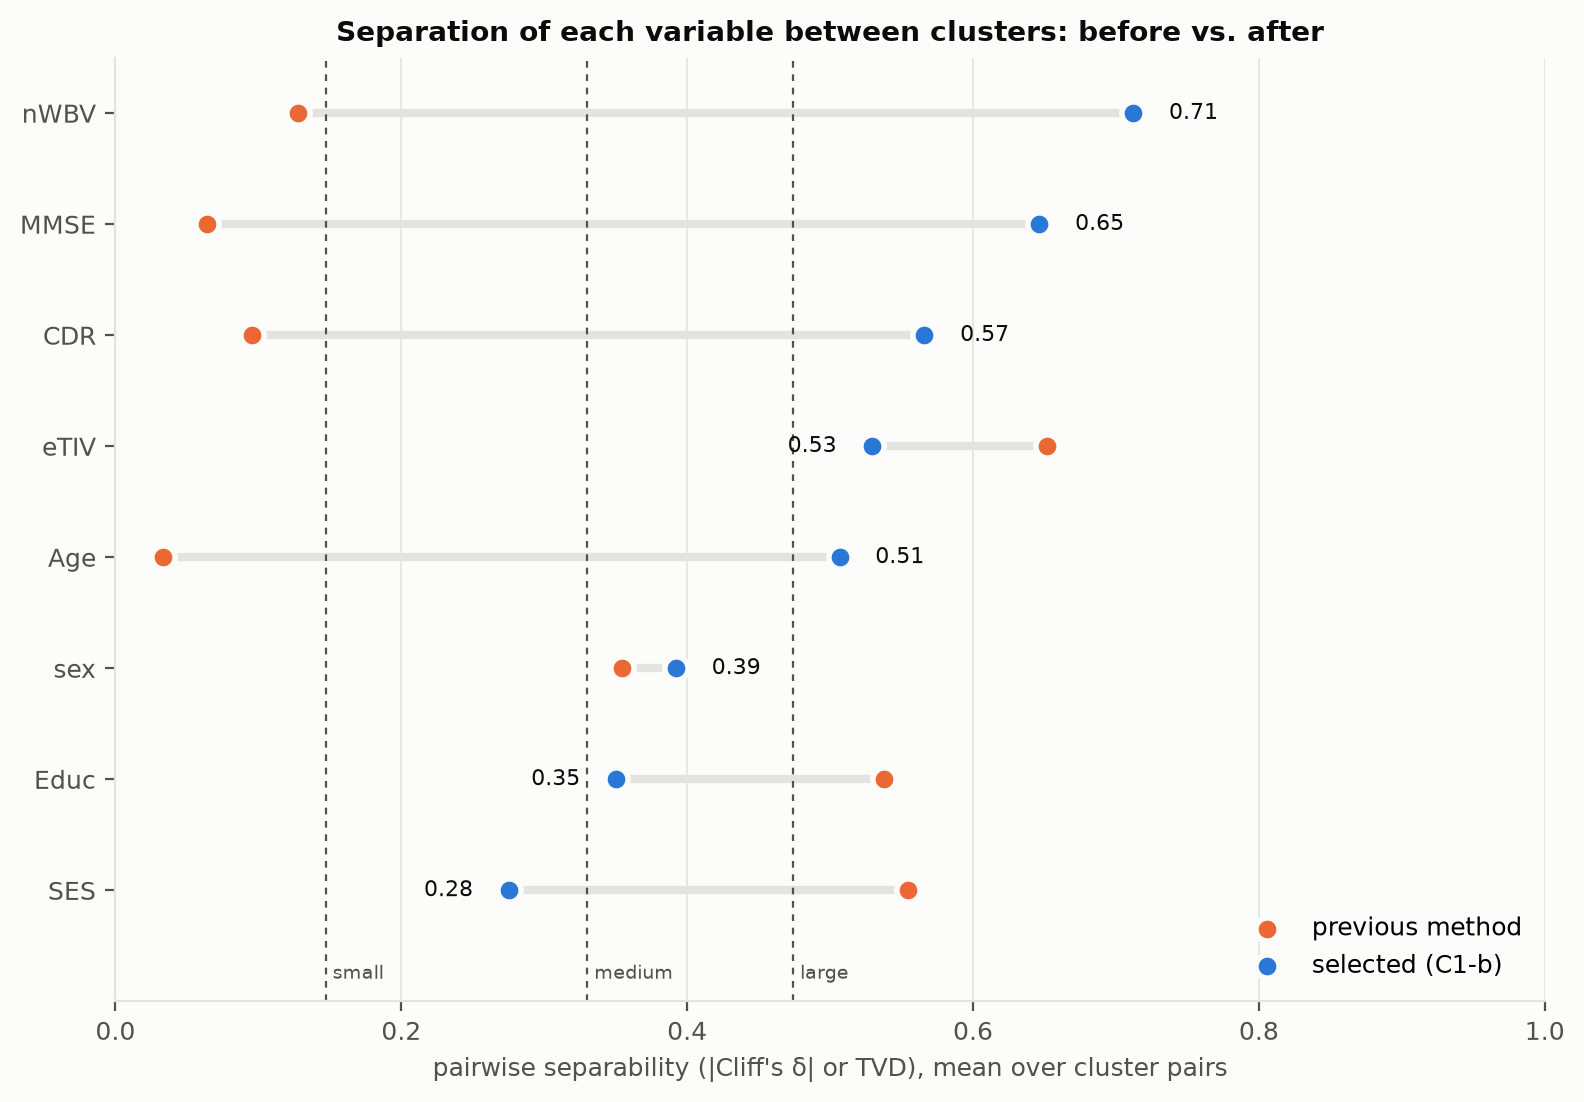

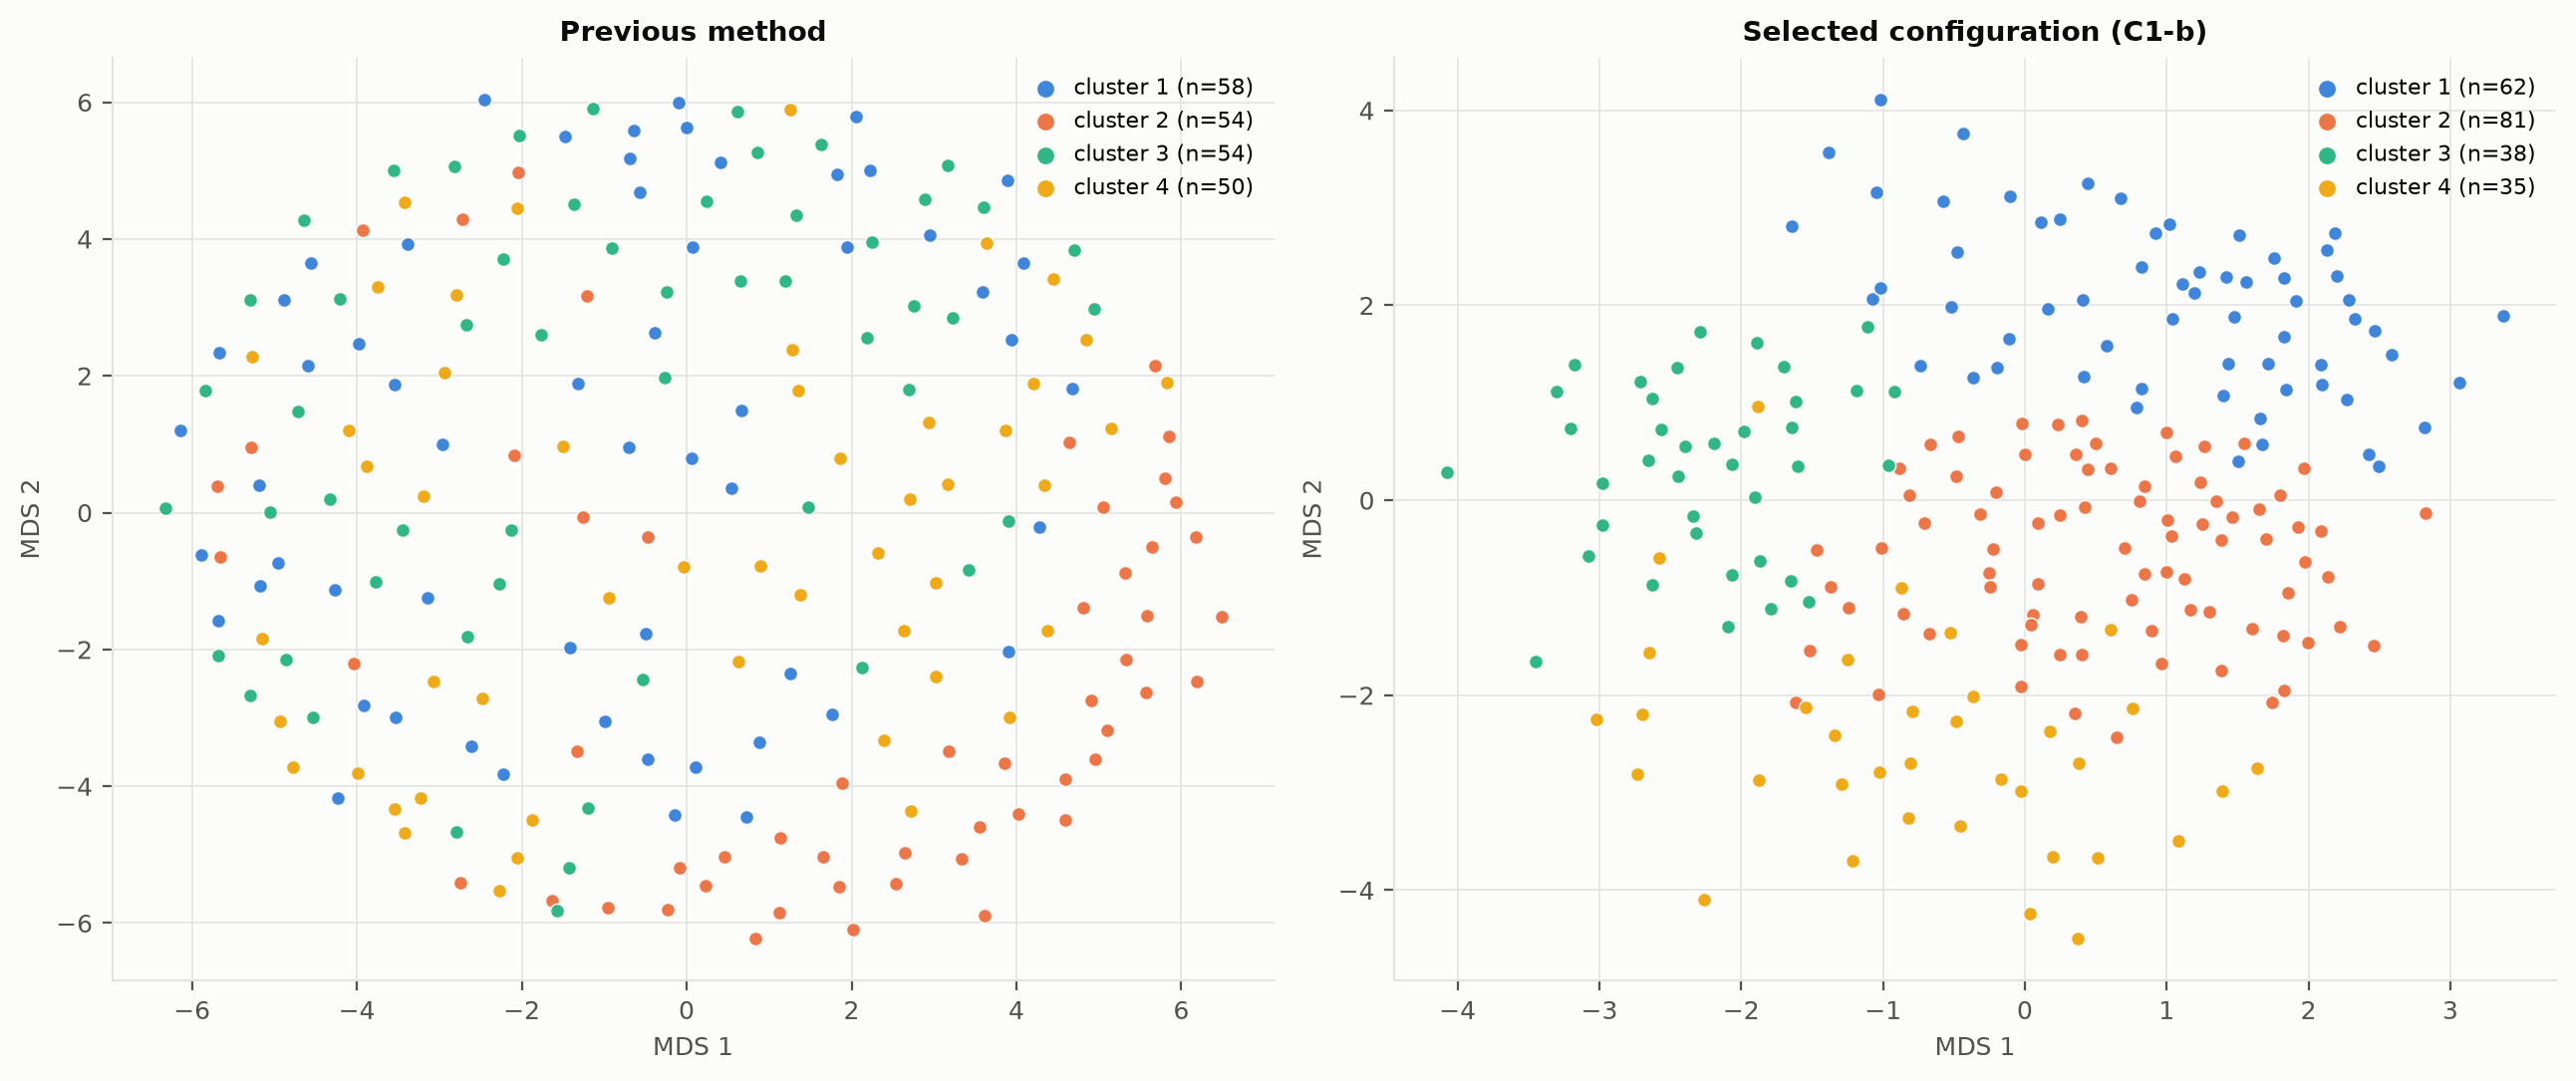

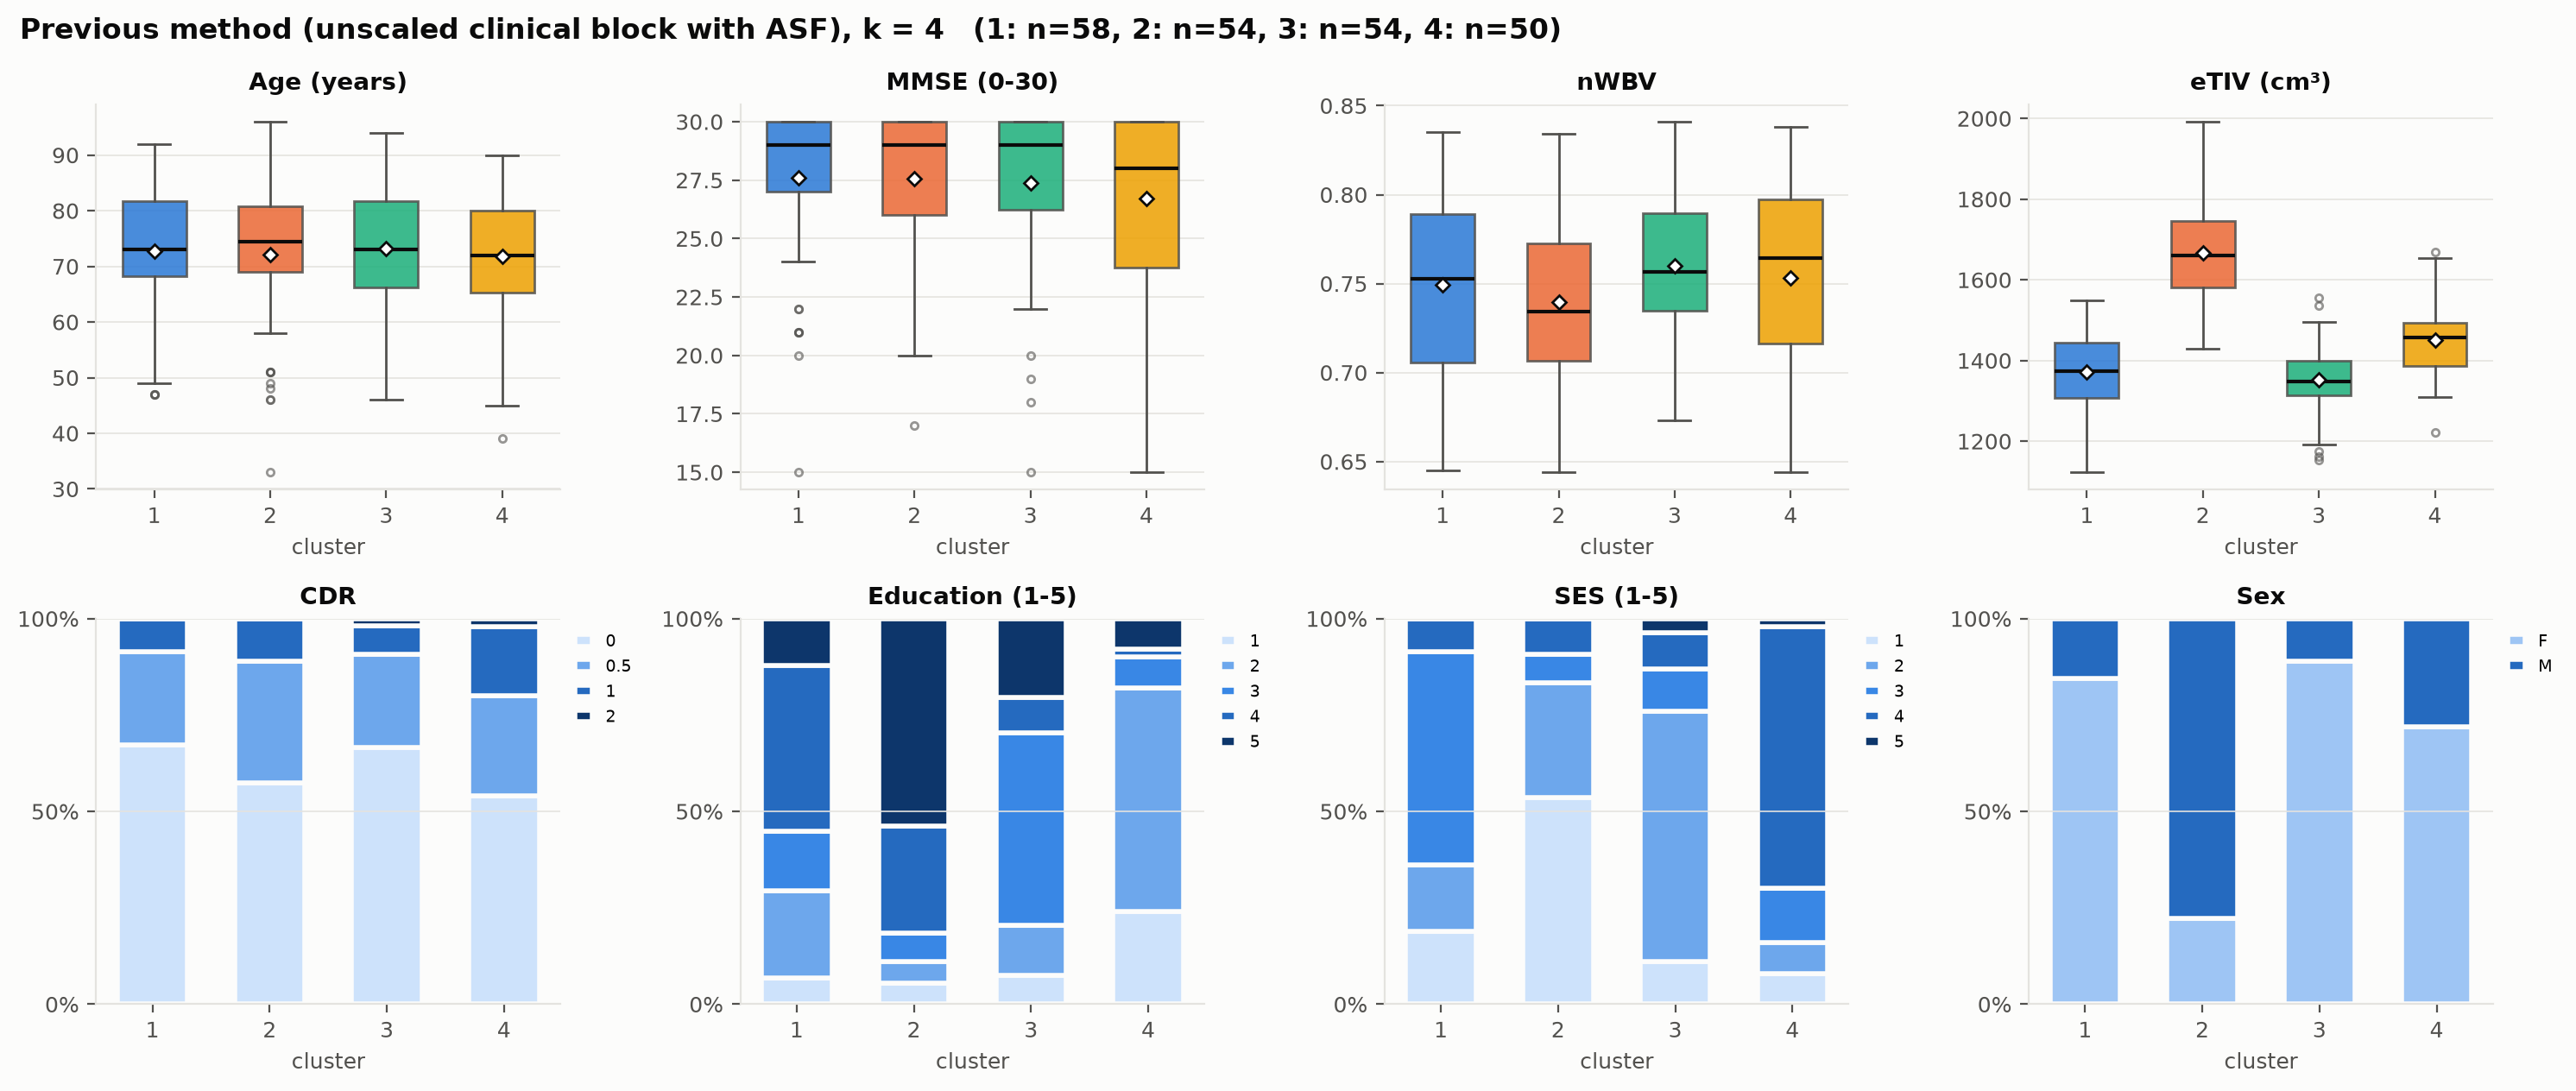

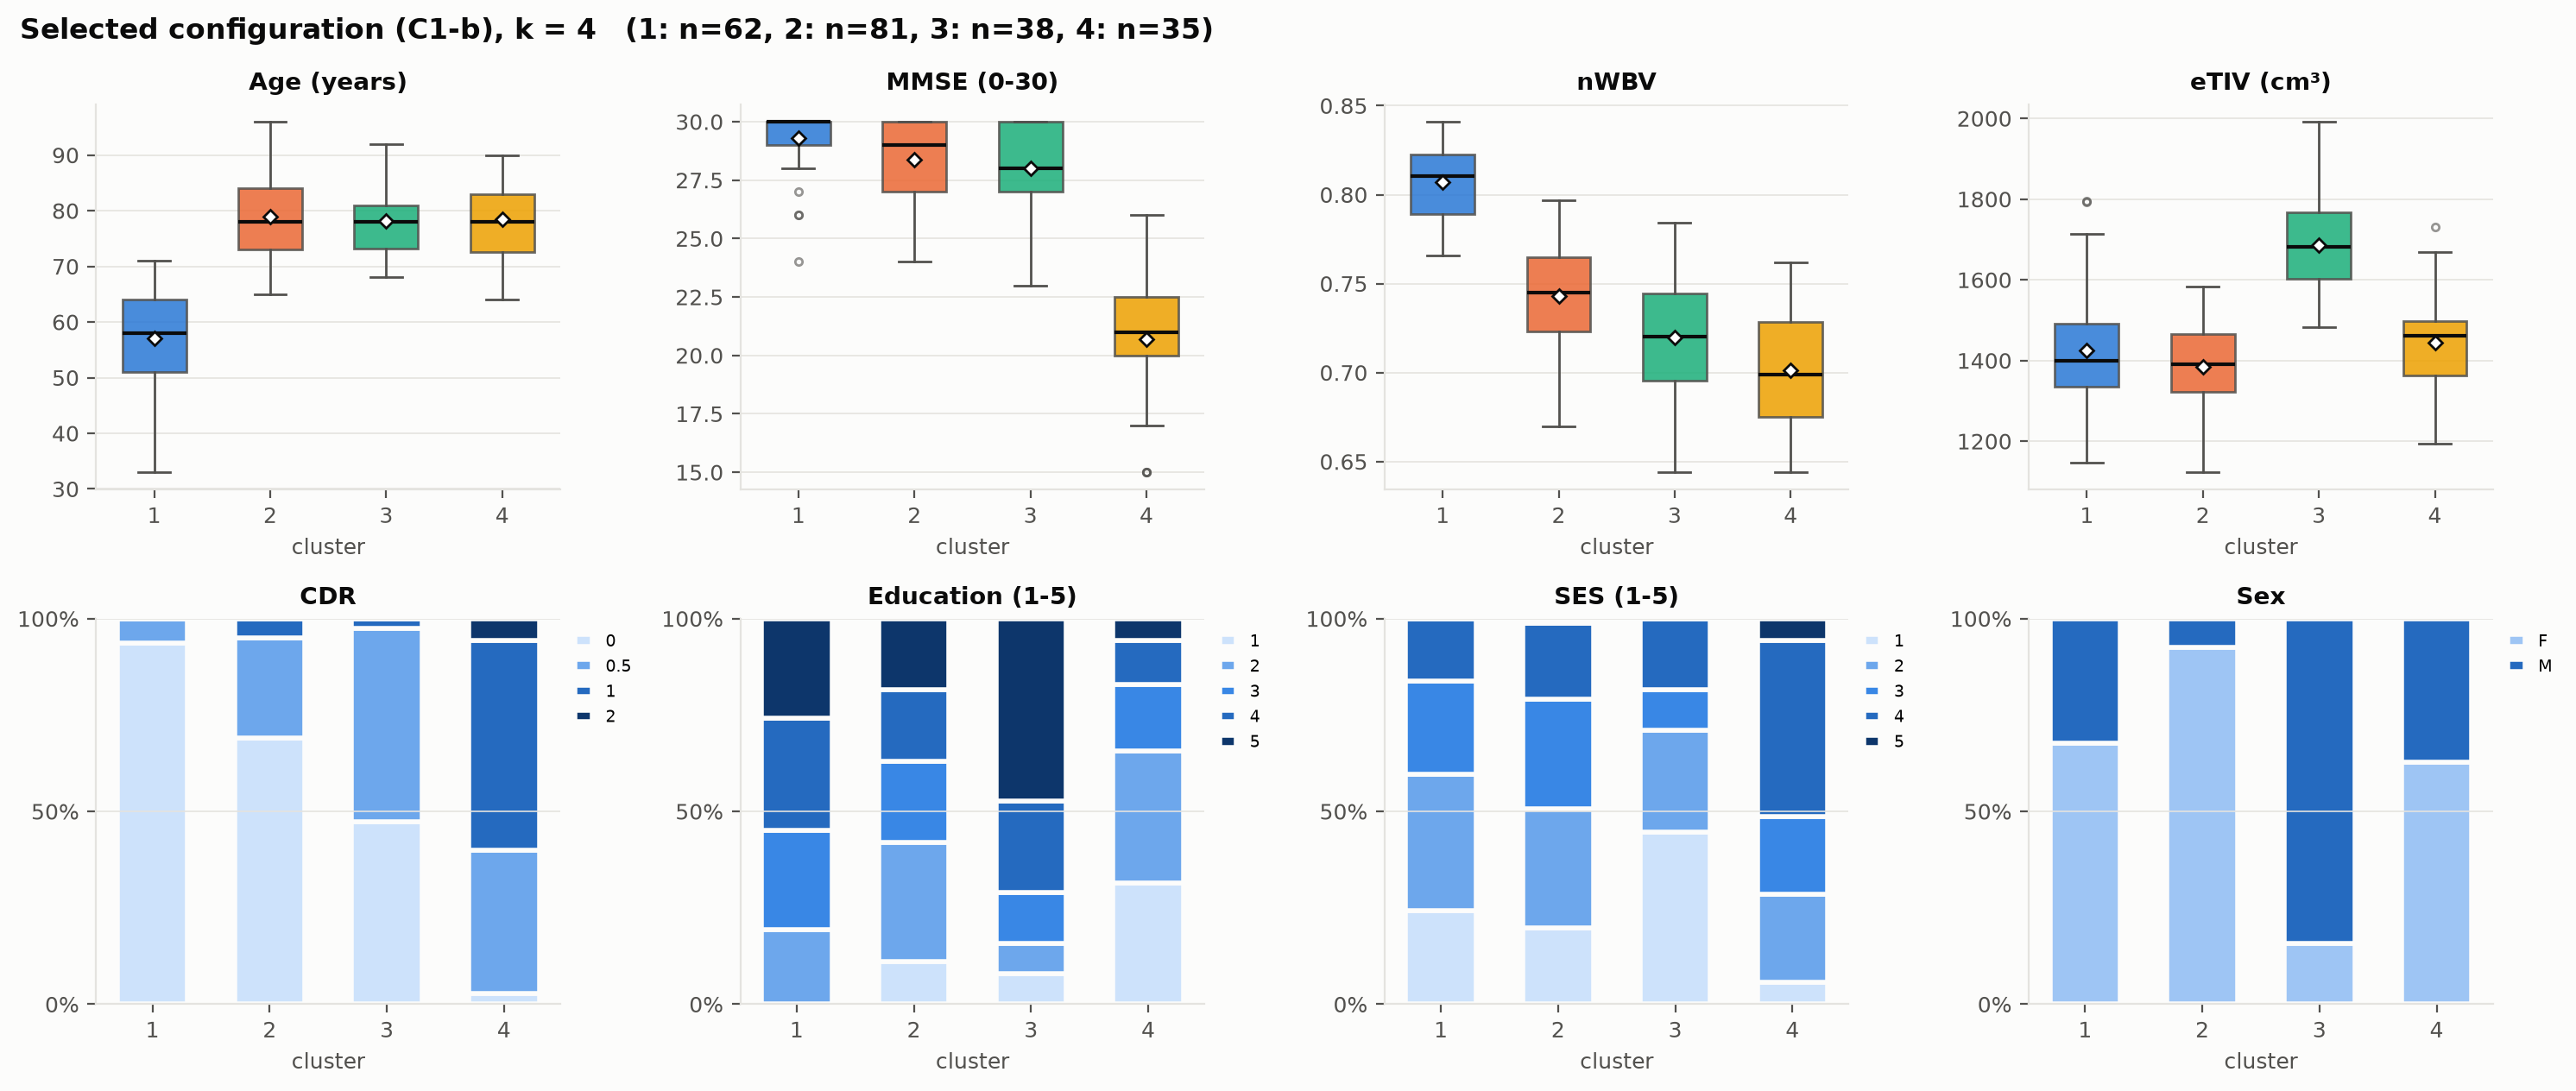

In [15]:
display(pd.read_csv(R / "07_before_after" / "psi_before_after.csv", index_col=0).T.round(3))
show_png(R / "07_before_after" / "psi_before_after.png", 750)
show_png(R / "07_before_after" / "mds_before_after.png")
show_png(R / "07_before_after" / "profile_before.png")
show_png(R / "07_before_after" / "profile_after.png")